In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [5]:
df = pd.read_csv("../data/cleaned/amazon_india_cleaned.csv", low_memory=False)
df.head()
print(df.shape)

(1127609, 35)


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1127609 entries, 0 to 1127608
Data columns (total 35 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   transaction_id          1127609 non-null  object 
 1   order_date              1019353 non-null  object 
 2   customer_id             1127609 non-null  object 
 3   product_id              1127609 non-null  object 
 4   product_name            1127609 non-null  object 
 5   category                1127609 non-null  object 
 6   subcategory             1127609 non-null  object 
 7   brand                   1127609 non-null  object 
 8   original_price_inr      1087400 non-null  float64
 9   discount_percent        1127609 non-null  float64
 10  discounted_price_inr    1127609 non-null  float64
 11  quantity                1127609 non-null  int64  
 12  subtotal_inr            1127609 non-null  float64
 13  delivery_charges        1127609 non-null  float64
 14  fi

# Question 1

Question 1
Create a comprehensive revenue trend analysis showing yearly revenue growth from 2015-2025. Include percentage growth rates, trend lines, and highlight key growth periods with annotations.

In [20]:
df['order_year'].unique()

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025])

In [21]:

yearly = df.groupby('order_year')['final_amount_inr'].sum().reset_index()

yearly

,order_year,final_amount_inr
0,2015,2.142163e+09
1,2016,3.598316e+09
2,2017,5.510026e+09
3,2018,7.248545e+09
4,2019,8.605901e+09
5,2020,1.187319e+10
6,2021,1.099021e+10
7,2022,8.532312e+09
8,2023,7.712999e+09
9,2024,6.823413e+09


In [22]:

yearly['growth_%'] = yearly['final_amount_inr'].pct_change() * 100
yearly

,order_year,final_amount_inr,growth_%
0,2015,2.142163e+09,NaN
1,2016,3.598316e+09,67.975780
2,2017,5.510026e+09,53.127907
3,2018,7.248545e+09,31.551925
4,2019,8.605901e+09,18.725908
5,2020,1.187319e+10,37.965735
6,2021,1.099021e+10,-7.436790
7,2022,8.532312e+09,-22.364427
8,2023,7.712999e+09,-9.602477
9,2024,6.823413e+09,-11.533590


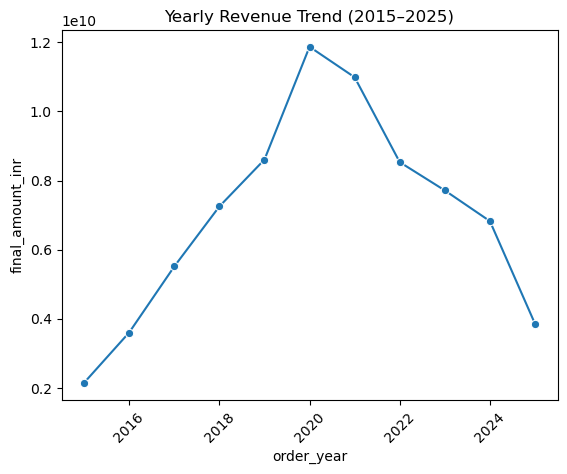

In [23]:
sns.lineplot(
    data=yearly,
    x='order_year',
    y='final_amount_inr',
    marker='o'
)

plt.title("Yearly Revenue Trend (2015–2025)")
plt.xticks(rotation=45)
plt.show()

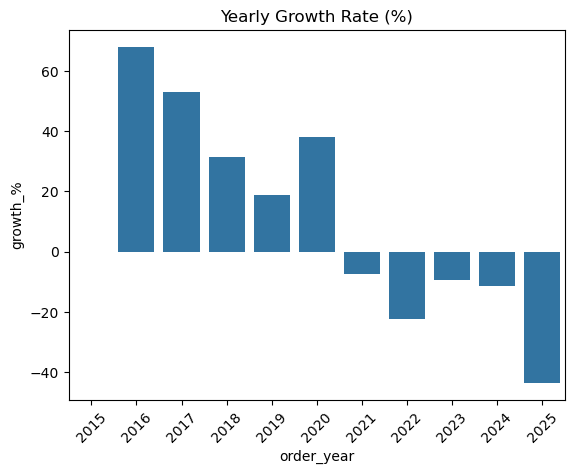

In [24]:

sns.barplot(
    data=yearly,
    x='order_year',
    y='growth_%'
)

plt.title("Yearly Growth Rate (%)")
plt.xticks(rotation=45)
plt.show()

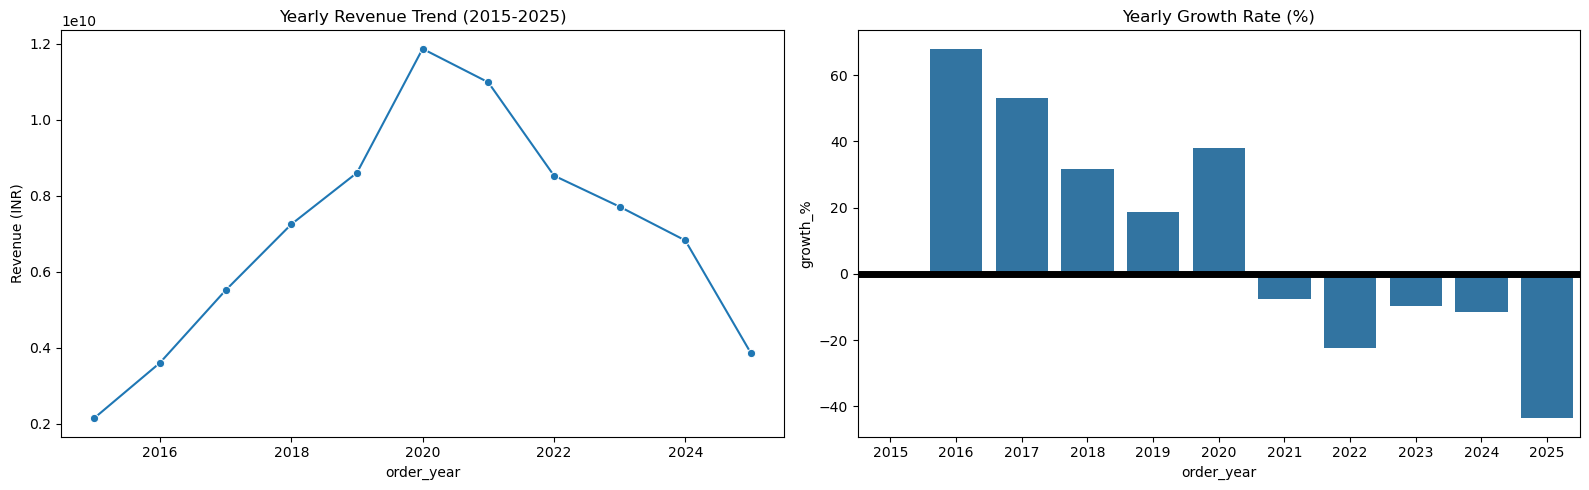

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.lineplot(data=yearly, x='order_year', y='final_amount_inr', marker='o', ax=axes[0])
axes[0].set_title('Yearly Revenue Trend (2015-2025)')
axes[0].set_ylabel('Revenue (INR)')

sns.barplot(data=yearly, x='order_year', y='growth_%', ax=axes[1])
axes[1].set_title('Yearly Growth Rate (%)')
axes[1].axhline(0, color='black', linewidth=5)
plt.tight_layout()
plt.show()

# Question 2

Question 2
Analyze seasonal patterns in sales data. Create monthly sales heatmaps and identify peak selling months. Compare seasonal trends across different years and categories.

In [127]:
df['order_month'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12])

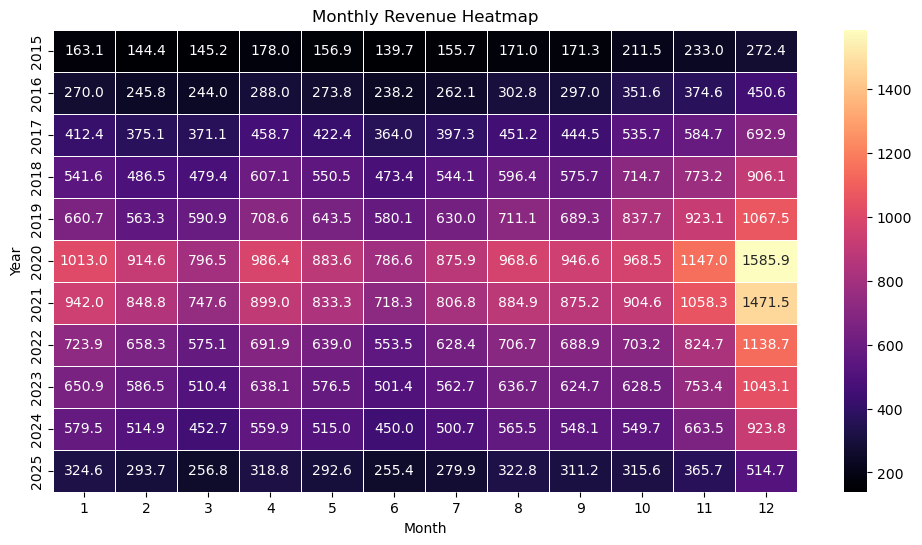

Peak selling month across all years: 12


In [130]:
seasonal = df.groupby(['order_year', 'order_month'])['final_amount_inr'].sum().reset_index()
pivot = seasonal.pivot(index='order_year', columns='order_month', values='final_amount_inr')

plt.figure(figsize=(12, 6))
heatmap_data = pivot / 1000000
sns.heatmap(heatmap_data, cmap='magma',
    annot=True, linewidths=0.5, fmt='.1f')
plt.title('Monthly Revenue Heatmap')
plt.xlabel('Month')
plt.ylabel('Year')
plt.show()

peak_month = seasonal.groupby('order_month')['final_amount_inr'].sum().idxmax()
print('Peak selling month across all years:', peak_month)

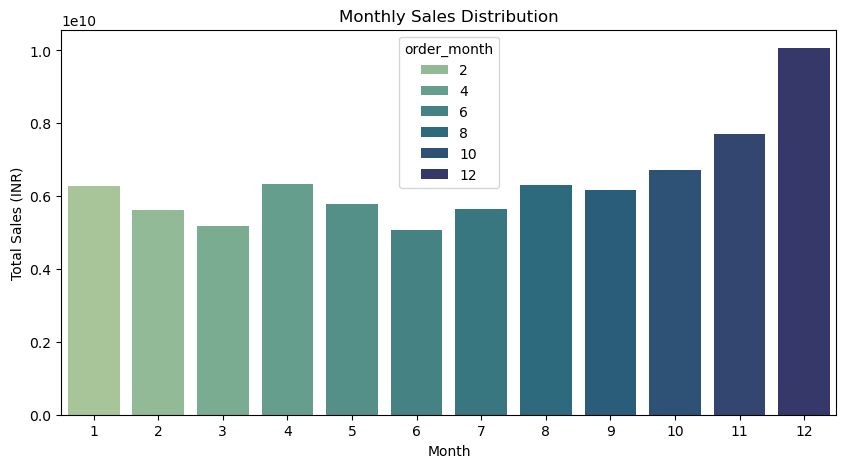

In [132]:
#Peak sales monthly
Monthly_sales=df.groupby('order_month')['final_amount_inr'].sum().reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(data=Monthly_sales, x='order_month', y='final_amount_inr', hue='order_month', palette='crest')
plt.title('Monthly Sales Distribution')
plt.xlabel('Month')
plt.ylabel('Total Sales (INR)')
plt.show()

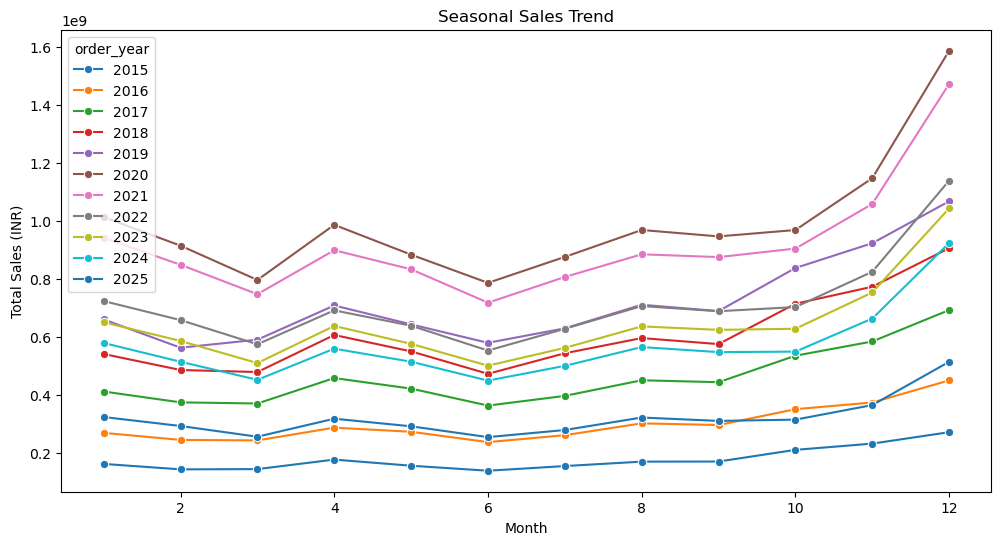

In [133]:
#seasonal trend analysis
monthly_sales_yearly = df.groupby(['order_year', 'order_month'])['final_amount_inr'].sum().reset_index()
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_sales_yearly, x='order_month', y='final_amount_inr', hue='order_year', palette='tab10',marker='o')
plt.title('Seasonal Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales (INR)')
plt.show()

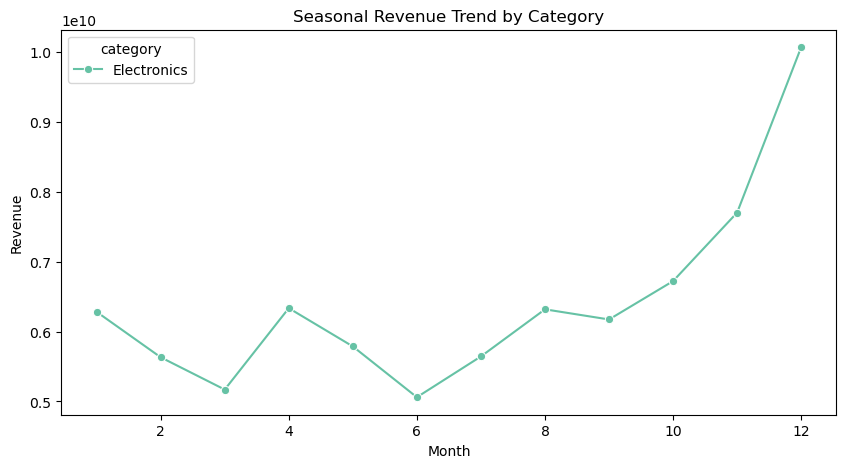

In [134]:
#categorical analysis
category_sales = df.groupby(['order_month', 'category'])['final_amount_inr'].sum().reset_index()
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=category_sales,
    x='order_month',
    y='final_amount_inr',
    hue='category',
    marker='o',
    palette='Set2'
)

plt.title('Seasonal Revenue Trend by Category')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.show()

# Question 3

Question 3
Design a Strategic Overview Dashboard showing market share analysis, competitive positioning, geographic expansion metrics, and business health indicators for C-level decision making.

In [ ]:
#first find the RFM Values
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed')
print(df['order_date'].dtype)

datetime64[ns]


In [ ]:
snapshot_date = df['order_date'].max() + pd.DateOffset(days=1)
print('Snapshot Date:', snapshot_date)

In [32]:
rfm=df.groupby('customer_id').agg(
    recency=('order_date', lambda x: (snapshot_date - x.max()).days),
    frequency=('transaction_id', 'count'),
    monetary=('final_amount_inr', 'sum')
).reset_index()

rfm.head()


,customer_id,recency,frequency,monetary
0,CUST_2015_00000001,2574.0,5,211034.56
1,CUST_2015_00000002,1156.0,10,632049.52
2,CUST_2015_00000003,3232.0,9,508294.02
3,CUST_2015_00000004,1640.0,8,812626.53
4,CUST_2015_00000005,2827.0,5,418011.46


In [33]:
#find rfm scores
rfm['recency_score']=pd.qcut(rfm['recency'], 4, labels=[4, 3, 2, 1])
rfm['frequency_score']=pd.qcut(rfm['frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4])
rfm['monetary_score']=pd.qcut(rfm['monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4])

In [34]:
#create customer segments based on RFM scores

rfm['RFM_total_Score'] = (
    pd.to_numeric(rfm['recency_score'], errors='coerce').fillna(0).astype(int) +
    pd.to_numeric(rfm['frequency_score'], errors='coerce').fillna(0).astype(int) +
    pd.to_numeric(rfm['monetary_score'], errors='coerce').fillna(0).astype(int)
)
def rfm_segment(score):
    if score >= 10:
        return 'Champions'
    elif score >= 8:
        return 'Loyal Customer'
    elif score >= 6:
        return 'Average Customer'
    
    else:
        return 'Risky Customer'

rfm['rfm_segment'] = rfm['RFM_total_Score'].apply(rfm_segment)
rfm.head()


,customer_id,recency,frequency,monetary,recency_score,frequency_score,monetary_score,RFM_total_Score,rfm_segment
0,CUST_2015_00000001,2574.0,5,211034.56,1,4,3,8,Loyal Customer
1,CUST_2015_00000002,1156.0,10,632049.52,3,4,4,11,Champions
2,CUST_2015_00000003,3232.0,9,508294.02,1,4,4,9,Loyal Customer
3,CUST_2015_00000004,1640.0,8,812626.53,2,4,4,10,Champions
4,CUST_2015_00000005,2827.0,5,418011.46,1,4,4,9,Loyal Customer


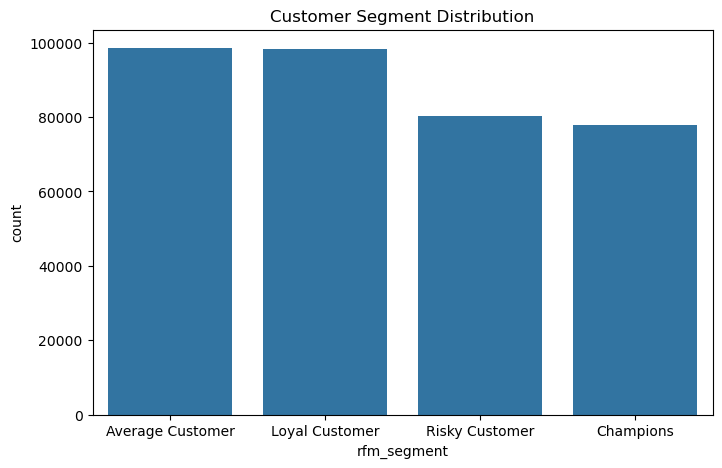

In [36]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=rfm,
    x='rfm_segment',
    order=rfm['rfm_segment'].value_counts().index
)

plt.title("Customer Segment Distribution")
plt.show()

In [135]:
rfm.head()

,customer_id,recency,frequency,monetary,recency_score,frequency_score,monetary_score,RFM_total_Score,rfm_segment
0,CUST_2015_00000001,2574.0,5,211034.56,1,4,3,8,Loyal Customer
1,CUST_2015_00000002,1156.0,10,632049.52,3,4,4,11,Champions
2,CUST_2015_00000003,3232.0,9,508294.02,1,4,4,9,Loyal Customer
3,CUST_2015_00000004,1640.0,8,812626.53,2,4,4,10,Champions
4,CUST_2015_00000005,2827.0,5,418011.46,1,4,4,9,Loyal Customer


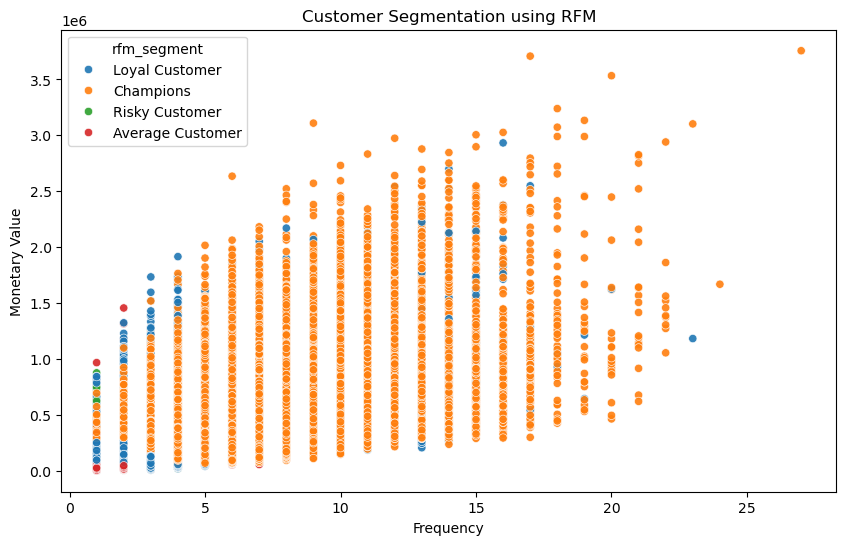

In [137]:
#RFM Segmentation Scatter Plot
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=rfm,
    x='frequency',
    y='monetary',
    alpha=0.9,
    hue='rfm_segment'
    
)

plt.title("Customer Segmentation using RFM")
plt.xlabel("Frequency")
plt.ylabel("Monetary Value")
plt.show()

<Figure size 1000x500 with 0 Axes>

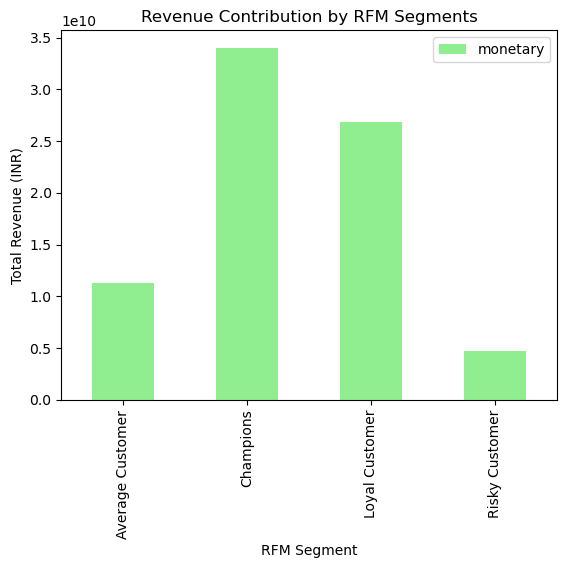

In [38]:
#Revenue Contribution by RFM Segments
segment_revenue = rfm.groupby('rfm_segment')['monetary'].sum().reset_index()
plt.figure(figsize=(10, 5))
segment_revenue.plot(kind='bar', x='rfm_segment', y='monetary', color='lightgreen')
plt.title("Revenue Contribution by RFM Segments")
plt.xlabel("RFM Segment")
plt.ylabel("Total Revenue (INR)")
plt.show()

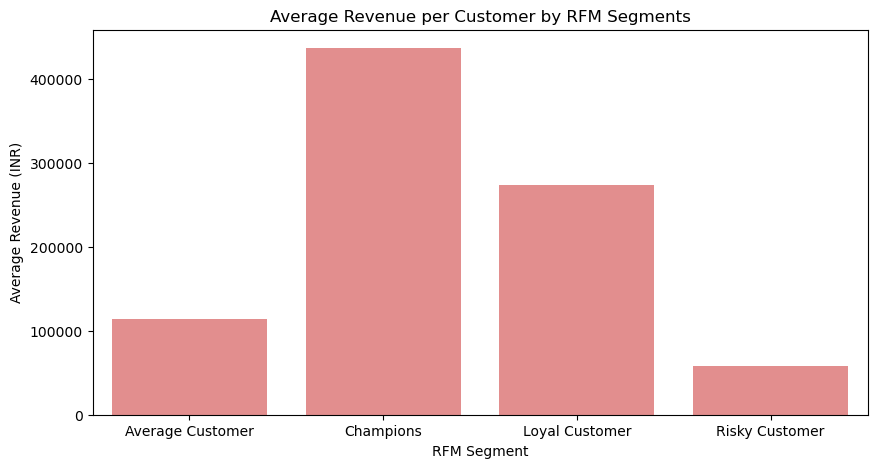

In [39]:
#Average Revenue per Customer by RFM Segments
avg_revenue_per_customer = rfm.groupby('rfm_segment')['monetary'].mean().reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(data=avg_revenue_per_customer, x='rfm_segment', y='monetary', color='lightcoral')
plt.title("Average Revenue per Customer by RFM Segments")
plt.xlabel("RFM Segment")
plt.ylabel("Average Revenue (INR)")
plt.show()

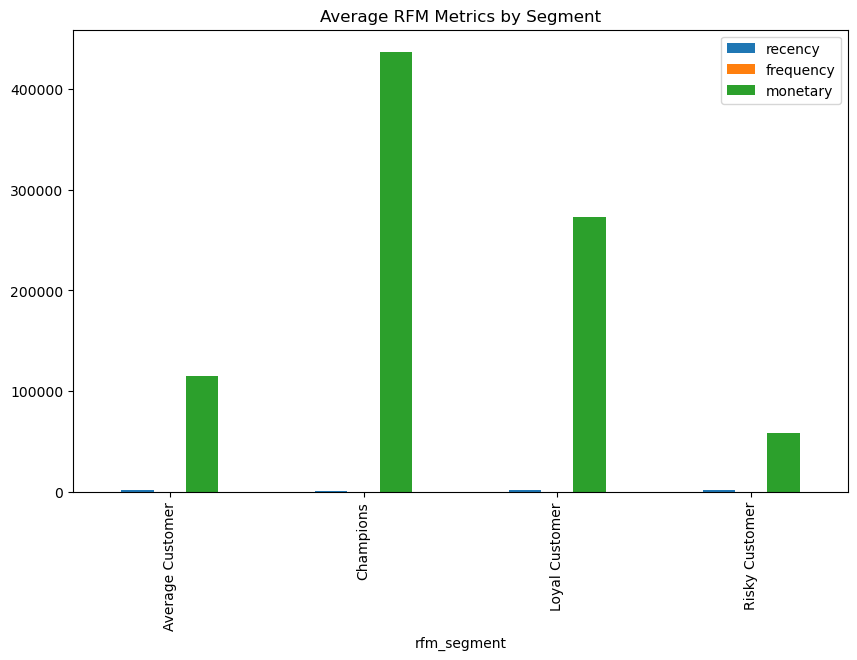

In [40]:
segment_metrics = rfm.groupby('rfm_segment')[
    ['recency','frequency','monetary']
].mean()

segment_metrics.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title("Average RFM Metrics by Segment")
plt.show()

# Question 4

Question 4
Visualize the evolution of payment methods from 2015-2025. Show the rise of UPI, decline of COD, and create stacked area charts to demonstrate market share changes over time.

In [138]:
# Payment Method Analysis
payment_counts=df['payment_method'].value_counts()
payment_counts


payment_method
UPI            384228
COD            322831
Credit Card    172261
Debit Card     140202
Net Banking     64971
Wallet          22821
BNPL            20295
Name: count, dtype: int64

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\1405748322.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=payment_counts.index, y=payment_counts.values, palette='pastel')


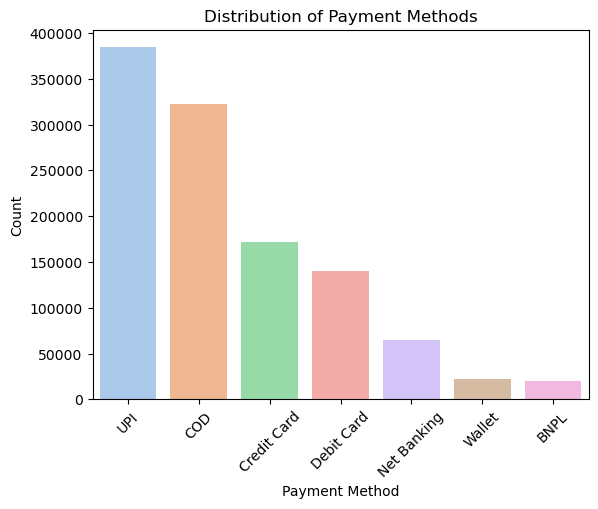

In [42]:
sns.barplot(x=payment_counts.index, y=payment_counts.values, palette='pastel')
plt.xlabel('Payment Method')
plt.ylabel('Count')
plt.title('Distribution of Payment Methods')
plt.xticks(rotation=45)
plt.show()

In [43]:
#Payment Method Analysis by Year
payment_shared=df.groupby(['order_year', 'payment_method']).size().reset_index(name='orders')
payment_shared                                                                          

,order_year,payment_method,orders
0,2015,COD,24962
1,2015,Credit Card,4008
2,2015,Debit Card,2599
3,2015,Net Banking,1596
4,2016,COD,38735
...,...,...,...
59,2025,Credit Card,9286
60,2025,Debit Card,6225
61,2025,Net Banking,2285
62,2025,UPI,46539


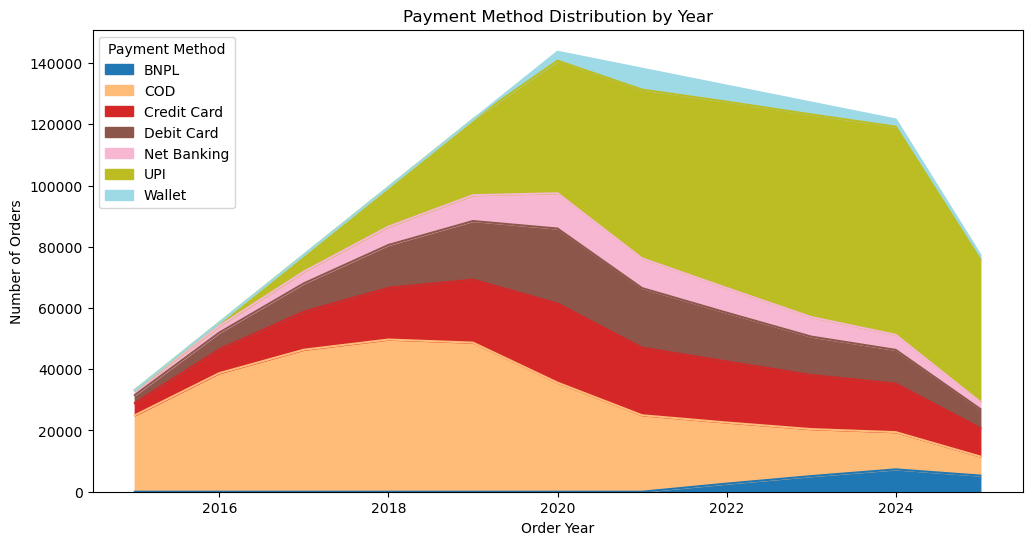

In [140]:
pivot_data=payment_shared.pivot(index='order_year', columns='payment_method', values='orders').fillna(0)
pivot_data.plot(kind='area', stacked=True, figsize=(12, 6), colormap='tab20')
plt.xlabel('Order Year')
plt.ylabel('Number of Orders')
plt.title('Payment Method Distribution by Year')
plt.legend(title='Payment Method')
plt.show()

In [141]:
pivot_data.head()

payment_method,BNPL,COD,Credit Card,Debit Card,Net Banking,UPI,Wallet
order_year,,,,,,,
2015,0.0,24962.0,4008.0,2599.0,1596.0,0.0,0.0
2016,0.0,38735.0,7789.0,5462.0,2152.0,1137.0,0.0
2017,0.0,46386.0,12419.0,9258.0,3851.0,5471.0,0.0
2018,0.0,49707.0,16879.0,14009.0,6005.0,12895.0,0.0
2019,0.0,48696.0,20571.0,19147.0,8454.0,24737.0,0.0


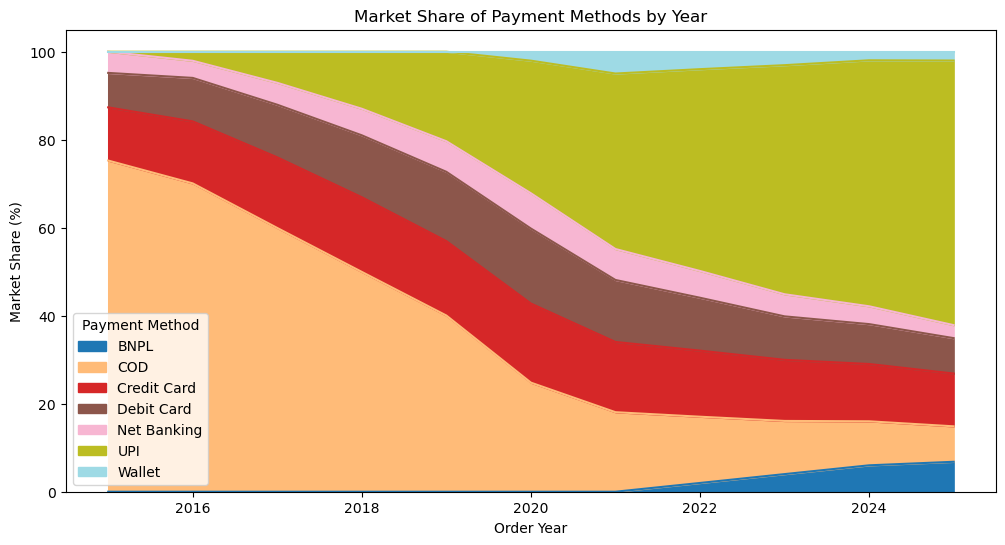

In [45]:
#MArket Share Analysis
share_pct=pivot_data.div(pivot_data.sum(axis=1), axis=0) * 100
share_pct.plot(kind='area', stacked=True, figsize=(12, 6), colormap='tab20')
plt.xlabel('Order Year')
plt.ylabel('Market Share (%)')
plt.title('Market Share of Payment Methods by Year')
plt.legend(title='Payment Method')
plt.show()

In [46]:
df['payment_method'].unique()

array(['COD', 'Debit Card', 'Credit Card', 'Net Banking', 'UPI', 'Wallet',
       'BNPL'], dtype=object)

In [143]:
payment_shared.head()

,order_year,payment_method,orders
0,2015,COD,24962
1,2015,Credit Card,4008
2,2015,Debit Card,2599
3,2015,Net Banking,1596
4,2016,COD,38735


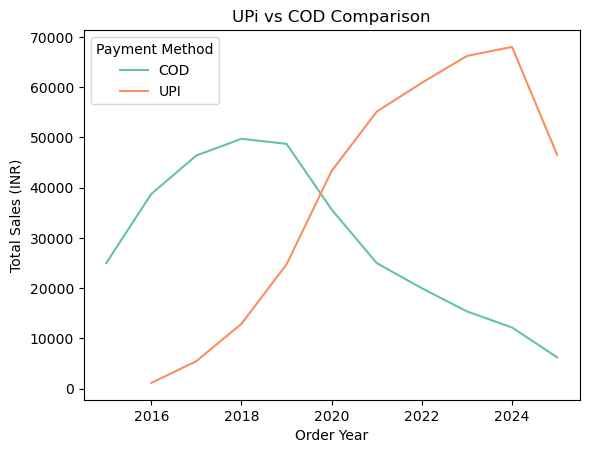

In [47]:
#upi vs cod comparison
upi_cod_df = payment_shared[payment_shared['payment_method'].isin(['UPI', 'COD'])]
sns.lineplot(data=upi_cod_df, x='order_year', y='orders', hue='payment_method', palette='Set2')
plt.xlabel('Order Year')

plt.ylabel('Total Sales (INR)')
plt.title('UPi vs COD Comparison')
plt.legend(title='Payment Method')
plt.show()

# Question 5

Question 5
Perform category-wise performance analysis. Create treemaps, bar charts, and pie charts showing revenue contribution, growth rates, and market share for each product category.

In [144]:
df['subcategory'].unique()

array(['Smartphones', 'Laptops', 'Tablets', 'Smart Watch', 'Audio',
       'TV & Entertainment'], dtype=object)

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\847444150.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




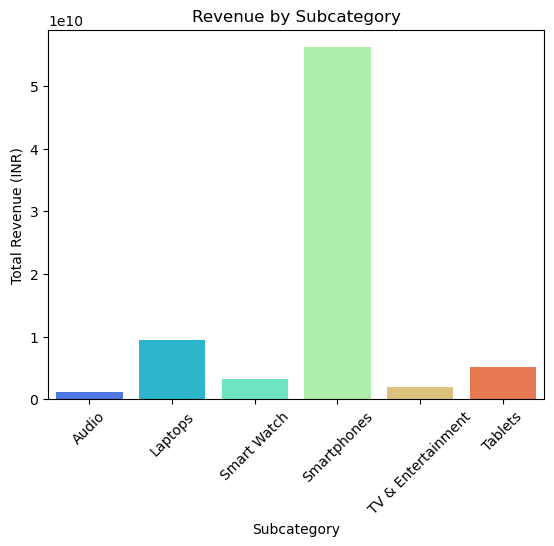

In [145]:
#Revenue by Subcategory
subcat=df.groupby('subcategory')['final_amount_inr'].sum().reset_index()
sns.barplot(data=subcat, x='subcategory', y='final_amount_inr', palette='rainbow')
plt.title('Revenue by Subcategory')
plt.xlabel('Subcategory')
plt.ylabel('Total Revenue (INR)')
plt.xticks(rotation=45)
plt.show()

In [146]:
subcat_share=subcat.copy()
subcat_share

,subcategory,final_amount_inr
0,Audio,1.111227e+09
1,Laptops,9.404032e+09
2,Smart Watch,3.215059e+09
3,Smartphones,5.615210e+10
4,TV & Entertainment,1.923418e+09
5,Tablets,5.082893e+09


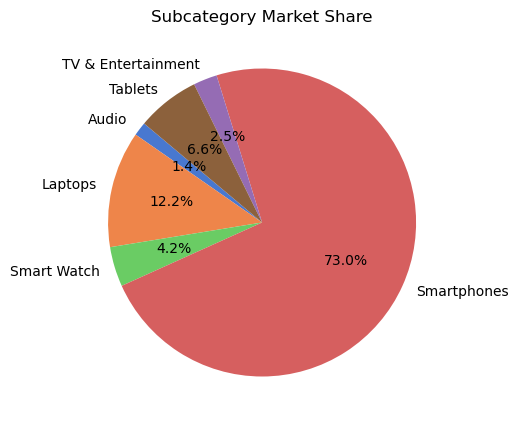

In [147]:
#Subcatergory Market Share Analysis

plt.figure(figsize=(10, 5))
plt.pie(subcat_share['final_amount_inr'], labels=subcat_share['subcategory'], 
        autopct='%1.1f%%', startangle=140, colors=sns.color_palette('muted'))
plt.title('Subcategory Market Share')
plt.show()


In [50]:
#Treemap 
import plotly.express as px
treemap=df.groupby(['subcategory', 'category'])['final_amount_inr'].sum().reset_index()
fig = px.treemap(treemap, path=['category', 'subcategory'], 
                 values='final_amount_inr', color='final_amount_inr', 
                 color_continuous_scale='RdBu')
fig.update_layout(title='Revenue Treemap by Category and Subcategory')
fig.show()

In [148]:
subcat_yearly=df.groupby(['order_year', 'subcategory'])['final_amount_inr'].sum().reset_index()
subcat_yearly

,order_year,subcategory,final_amount_inr
0,2015,Audio,1.780509e+07
1,2015,Laptops,3.238882e+08
2,2015,Smart Watch,1.405078e+08
3,2015,Smartphones,1.409419e+09
4,2015,TV & Entertainment,6.198430e+07
...,...,...,...
61,2025,Laptops,4.258168e+08
62,2025,Smart Watch,2.101729e+08
63,2025,Smartphones,2.821509e+09
64,2025,TV & Entertainment,8.310632e+07


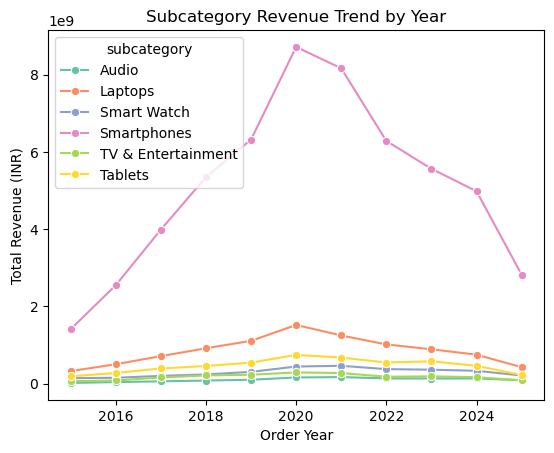

In [150]:
#Subcatergory Revenue Trend By Year
sns.lineplot(data=subcat_yearly, x='order_year', y='final_amount_inr', hue='subcategory', palette='Set2', marker='o')
plt.title('Subcategory Revenue Trend by Year')
plt.xlabel('Order Year')
plt.ylabel('Total Revenue (INR)')
plt.show()


# Question 6

Question 6
Analyze Prime membership impact on customer behavior. Compare average order values, order frequency, and category preferences between Prime and non-Prime customers using multiple visualization types.

In [151]:
df['is_prime_eligible'].unique()

array([ True, False])

In [ ]:
#Create Prime Member vs Non-Prime Member Analysis
prime_analysis=df.groupby('is_prime_eligible').agg(
    AOV=('final_amount_inr', 'mean'),
    Total_Revenue=('final_amount_inr', 'sum'),
    Frequency=('transaction_id', 'count')
).reset_index()
prime_analysis



,is_prime_eligible,AOV,Total_Revenue,Frequency
0,False,72009.385948,1.468581e+10,203943
1,True,67343.519589,6.220292e+10,923666


C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\706504949.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




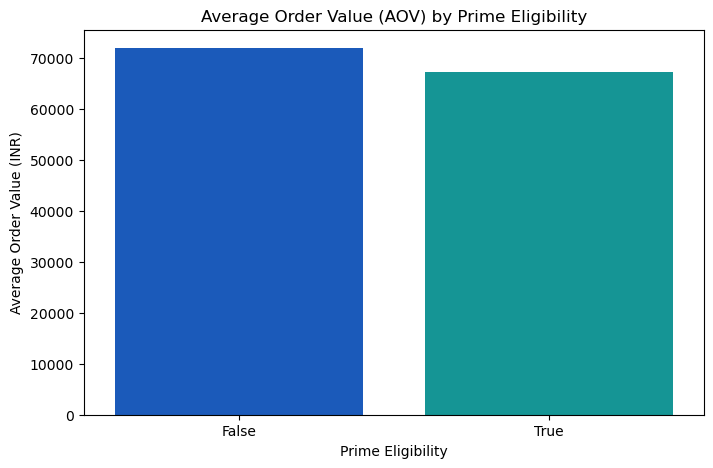

In [54]:
#Average Order Value (AOV) prime vs non-prime
plt.figure(figsize=(8, 5))
sns.barplot(data=prime_analysis, x='is_prime_eligible', y='AOV', palette='winter')
plt.title('Average Order Value (AOV) by Prime Eligibility')
plt.xlabel('Prime Eligibility')
plt.ylabel('Average Order Value (INR)')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\2841313993.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




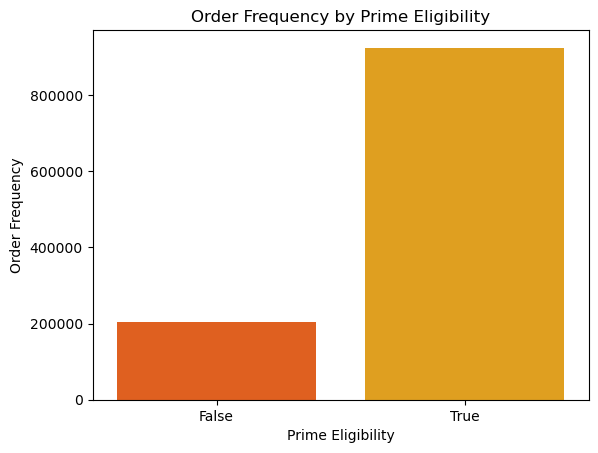

In [55]:
#order frequency prime vs non-prime
sns.barplot(data=prime_analysis, x='is_prime_eligible', y='Frequency', palette='autumn')
plt.title('Order Frequency by Prime Eligibility')
plt.xlabel('Prime Eligibility')
plt.ylabel('Order Frequency')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\3043263620.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




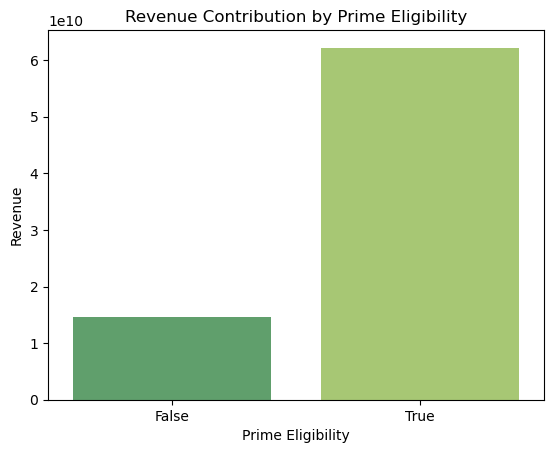

In [56]:
#Revenue Contribution by Prime Eligibility
sns.barplot(data=prime_analysis, x='is_prime_eligible', y='Total_Revenue', palette='summer')
plt.title('Revenue Contribution by Prime Eligibility')
plt.xlabel('Prime Eligibility')
plt.ylabel('Revenue')
plt.show()

In [152]:
subcat_prime=df.groupby(['is_prime_eligible', 'subcategory'])['final_amount_inr'].sum().reset_index()
subcat_prime

,is_prime_eligible,subcategory,final_amount_inr
0,False,Audio,1.995017e+08
1,False,Laptops,2.693879e+09
2,False,Smart Watch,8.721681e+08
3,False,Smartphones,1.000648e+10
4,False,TV & Entertainment,1.635461e+08
5,False,Tablets,7.502357e+08
6,True,Audio,9.117255e+08
7,True,Laptops,6.710154e+09
8,True,Smart Watch,2.342891e+09
9,True,Smartphones,4.614562e+10


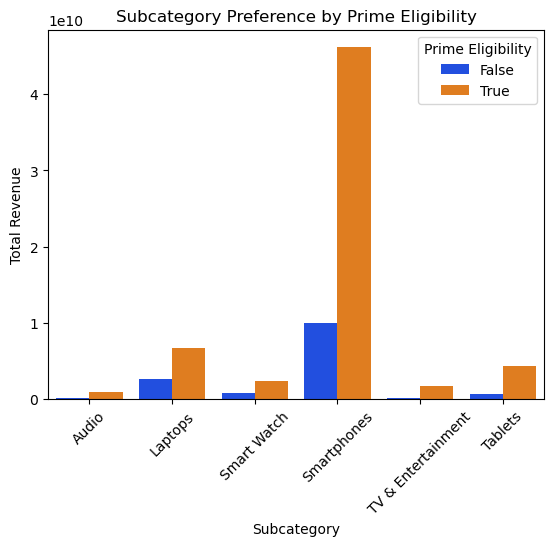

In [57]:
#Subcategory preference by Prime Eligibility
subcat_prime=df.groupby(['is_prime_eligible', 'subcategory'])['final_amount_inr'].sum().reset_index()
sns.barplot(data=subcat_prime, x='subcategory', y='final_amount_inr', hue='is_prime_eligible', palette='bright')
plt.title('Subcategory Preference by Prime Eligibility')
plt.xlabel('Subcategory')
plt.xticks(rotation=45)
plt.ylabel('Total Revenue')
plt.legend(title='Prime Eligibility')
plt.show()

# Question 7

Question 7
Create geographic analysis of sales performance across Indian cities and states. Build choropleth maps and bar charts showing revenue density and growth patterns by tier (Metro/Tier1/Tier2/Rural).

In [154]:
df['customer_state'].nunique()

15

In [58]:
#Revenue by state
state_revenue=df.groupby('customer_state')['final_amount_inr'].sum().reset_index()
state_revenue.value_counts()

customer_state  final_amount_inr
Andhra Pradesh  1.260290e+09        1
Bihar           1.191981e+09        1
Delhi           9.282344e+09        1
Gujarat         7.183017e+09        1
Karnataka       7.680945e+09        1
Kerala          1.429728e+09        1
Madhya Pradesh  2.214093e+09        1
Maharashtra     1.755014e+10        1
Odisha          1.159308e+09        1
Punjab          2.185799e+09        1
Rajasthan       2.644470e+09        1
Tamil Nadu      7.923753e+09        1
Telangana       3.335962e+09        1
Uttar Pradesh   6.793803e+09        1
West Bengal     5.053097e+09        1
Name: count, dtype: int64

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\1819663947.py:1: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




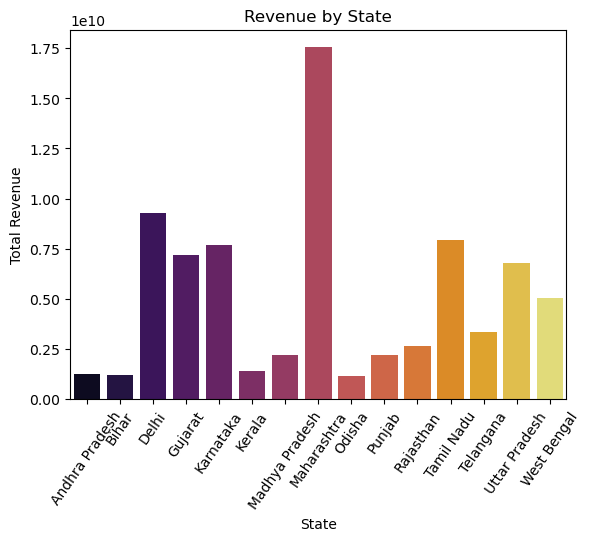

In [157]:
sns.barplot(data=state_revenue, x='customer_state', y='final_amount_inr', palette='inferno')
plt.title('Revenue by State')
plt.xlabel('State')
plt.ylabel('Total Revenue')
plt.xticks(rotation=55)
plt.show()

In [158]:
df['customer_tier'].unique()

array(['Metro', 'Rural', 'Tier2', 'Tier1'], dtype=object)

In [60]:
#Revenue by customer tier
tier_revenue=df.groupby('customer_tier')['final_amount_inr'].sum().reset_index()
tier_revenue.value_counts()

customer_tier  final_amount_inr
Metro          4.242541e+10        1
Rural          2.323583e+09        1
Tier1          2.218988e+10        1
Tier2          9.949852e+09        1
Name: count, dtype: int64

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\2854319782.py:1: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




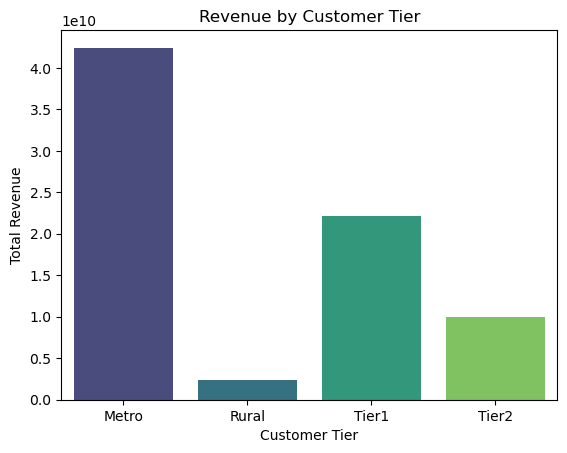

In [159]:
sns.barplot(data=tier_revenue, x='customer_tier', y='final_amount_inr', palette='viridis')
plt.title('Revenue by Customer Tier')
plt.xlabel('Customer Tier')
plt.ylabel('Total Revenue')
plt.show()

In [62]:
#Average Order Value (AOV) by Customer Tier
tier_aov=df.groupby('customer_tier')['final_amount_inr'].mean().reset_index()
tier_aov

,customer_tier,final_amount_inr
0,Metro,75245.175711
1,Rural,46479.103492
2,Tier1,65528.206667
3,Tier2,56805.334035


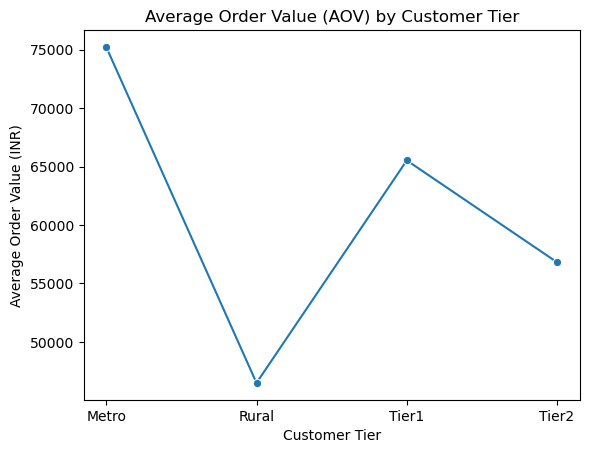

In [63]:
sns.lineplot(data=tier_aov, x='customer_tier', y='final_amount_inr', marker='o')
plt.title('Average Order Value (AOV) by Customer Tier')
plt.xlabel('Customer Tier')
plt.ylabel('Average Order Value (INR)')
plt.show()

In [161]:
geo_year=df.groupby(['customer_state', 'order_year'])['final_amount_inr'].sum().reset_index()
geo_year

,customer_state,order_year,final_amount_inr
0,Andhra Pradesh,2015,2.275590e+07
1,Andhra Pradesh,2016,3.893082e+07
2,Andhra Pradesh,2017,6.907986e+07
3,Andhra Pradesh,2018,9.747468e+07
4,Andhra Pradesh,2019,1.347370e+08
...,...,...,...
160,West Bengal,2021,6.980806e+08
161,West Bengal,2022,5.071194e+08
162,West Bengal,2023,4.422041e+08
163,West Bengal,2024,3.608204e+08


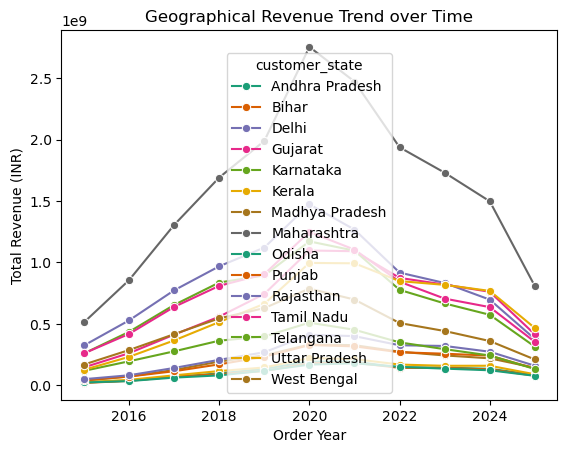

In [ ]:
#Geographical Trend over time
geo_year=df.groupby(['customer_state', 'order_year'])['final_amount_inr'].sum().reset_index()
sns.lineplot(data=geo_year, x='order_year', y='final_amount_inr', hue='customer_state', palette='Dark2', marker='o')
plt.title('Geographical Revenue Trend over Time')
plt.xlabel('Order Year')
plt.ylabel('Total Revenue (INR)')
plt.show()

# Question 8

Question 8
Study festival sales impact using before/during/after analysis. Visualize revenue spikes during Diwali, Prime Day, and other festivals with detailed time series analysis.

In [162]:
df['is_festival_sale'].unique()

array([ True, False])

In [65]:
#REvenue by FEstival SAles and non festival sales
festival_sales=df.groupby('is_festival_sale')['final_amount_inr'].sum().reset_index()
festival_sales.value_counts()

is_festival_sale  final_amount_inr
False             6.027034e+10        1
True              1.661839e+10        1
Name: count, dtype: int64

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\1279115490.py:1: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




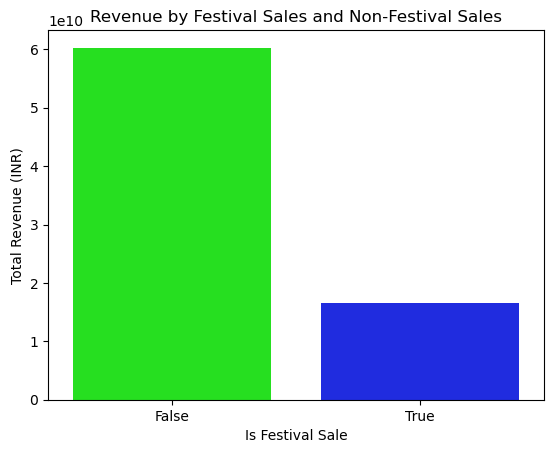

In [164]:
sns.barplot(data=festival_sales, x='is_festival_sale', y='final_amount_inr', palette='hsv')
plt.title('Revenue by Festival Sales and Non-Festival Sales')
plt.xlabel('Is Festival Sale')
plt.ylabel('Total Revenue (INR)')
plt.show()

In [168]:
festival_year=df.groupby(['order_year', 'is_festival_sale'])['final_amount_inr'].sum().reset_index()
festival_year

,order_year,is_festival_sale,final_amount_inr
0,2015,False,1.660440e+09
1,2015,True,4.817230e+08
2,2016,False,2.799337e+09
3,2016,True,7.989789e+08
4,2017,False,4.289465e+09
5,2017,True,1.220561e+09
6,2018,False,5.635679e+09
7,2018,True,1.612866e+09
8,2019,False,6.679310e+09
9,2019,True,1.926591e+09


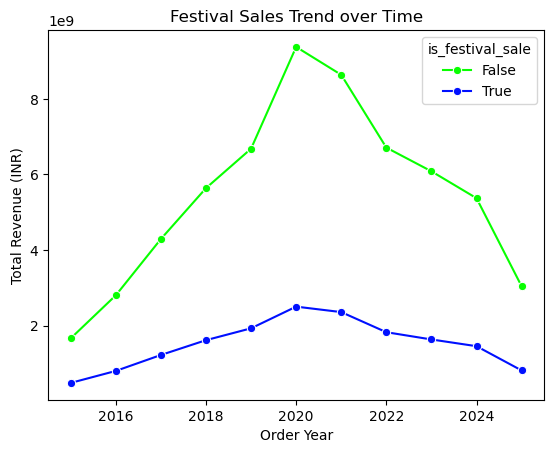

In [ ]:
#FEstival Sales Trend over time
sns.lineplot(data=festival_year, x='order_year', y='final_amount_inr', hue='is_festival_sale', palette='hsv', marker='o')
plt.title('Festival Sales Trend over Time')
plt.xlabel('Order Year')
plt.ylabel('Total Revenue (INR)')
plt.show()

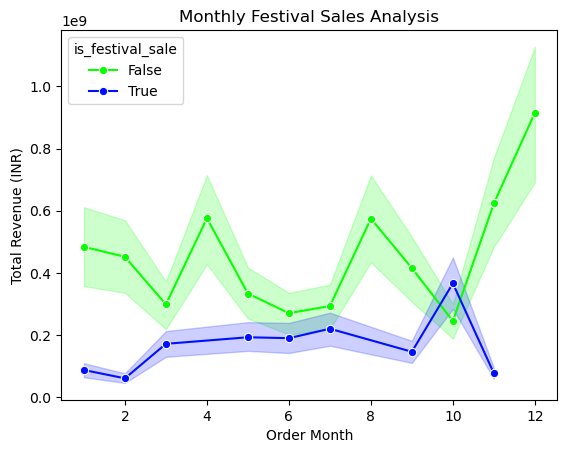

In [166]:
#MOnthly Festival Sales Analysis
monthly_festival_sales=df.groupby(['order_year', 'order_month', 'is_festival_sale'])['final_amount_inr'].sum().reset_index()
sns.lineplot(data=monthly_festival_sales, x='order_month', y='final_amount_inr', hue='is_festival_sale', palette='hsv', marker='o')
plt.title('Monthly Festival Sales Analysis')
plt.xlabel('Order Month')
plt.ylabel('Total Revenue (INR)')
plt.show()

In [169]:
df['festival_name'].unique()

array(['Republic Day Sale', 'No Festival', 'Valentine Sale',
       'Holi Festival', 'Summer Sale', 'Back to School', 'Prime Day',
       'Amazon Great Indian Festival', 'Diwali Sale'], dtype=object)

In [170]:
df['festival_name'].nunique()

9

In [171]:
festival_type = df.groupby('festival_name')['final_amount_inr'].sum().reset_index()
festival_type

,festival_name,final_amount_inr
0,Amazon Great Indian Festival,2.519912e+09
1,Back to School,4.072595e+09
2,Diwali Sale,3.958181e+09
3,Holi Festival,1.886839e+09
4,No Festival,6.027034e+10
5,Prime Day,4.360842e+08
6,Republic Day Sale,9.602263e+08
7,Summer Sale,2.119236e+09
8,Valentine Sale,6.653183e+08


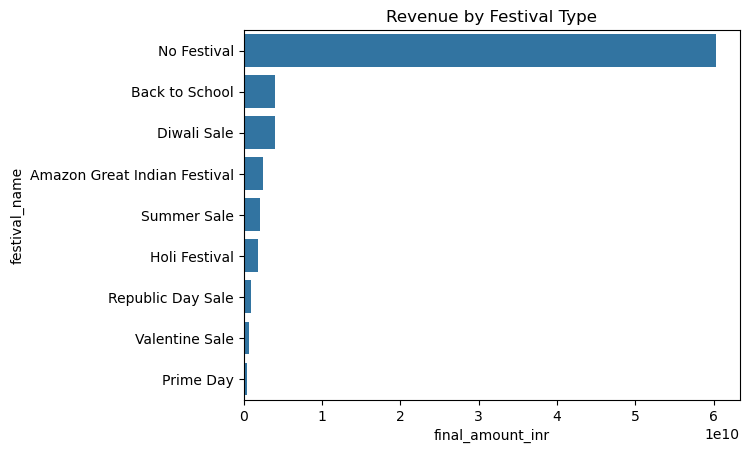

In [174]:
#Festival comparision
sns.barplot(
    data=festival_type.sort_values('final_amount_inr', ascending=False),
    x='final_amount_inr',
    y='festival_name'
)

plt.title("Revenue by Festival Type")
plt.show()
     

# Question 9

Question 9
Analyze customer age group behavior and preferences. Create demographic analysis with category preferences, spending patterns, and shopping frequency across different age segments.

In [176]:
df['customer_age_group'].unique()

array(['46-55', '26-35', '36-45', '18-25', '55+'], dtype=object)

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\699509391.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




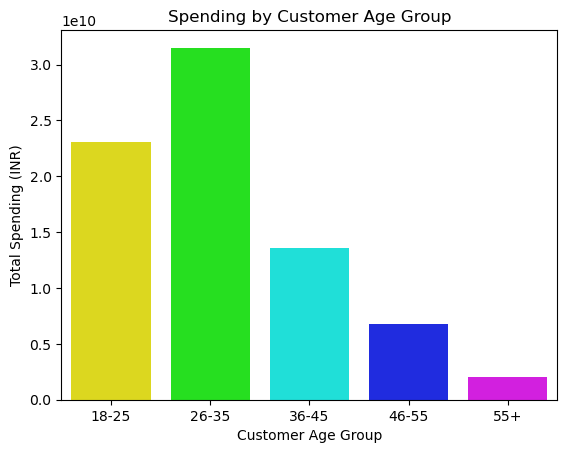

In [178]:
#Spending by customer age group 
age_group_spending = df.groupby('customer_age_group')['final_amount_inr'].sum().reset_index()
sns.barplot(data=age_group_spending, x='customer_age_group', y='final_amount_inr', palette='hsv')
plt.title('Spending by Customer Age Group')
plt.xlabel('Customer Age Group')
plt.ylabel('Total Spending (INR)')
plt.show()


C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\492763607.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




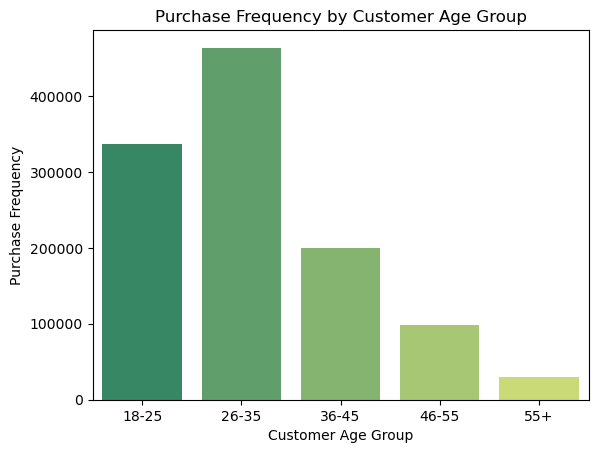

In [179]:
#Purchase Frequency by Customer Age Group
age_group_frequency = df.groupby('customer_age_group')['transaction_id'].count().reset_index()
sns.barplot(data=age_group_frequency, x='customer_age_group', y='transaction_id', palette='summer')
plt.title('Purchase Frequency by Customer Age Group')
plt.xlabel('Customer Age Group')
plt.ylabel('Purchase Frequency')
plt.show()

In [180]:
age_share=df.groupby('customer_age_group')['final_amount_inr'].sum().reset_index()
age_share

,customer_age_group,final_amount_inr
0,18-25,2.306689e+10
1,26-35,3.151386e+10
2,36-45,1.354794e+10
3,46-55,6.738845e+09
4,55+,2.021196e+09


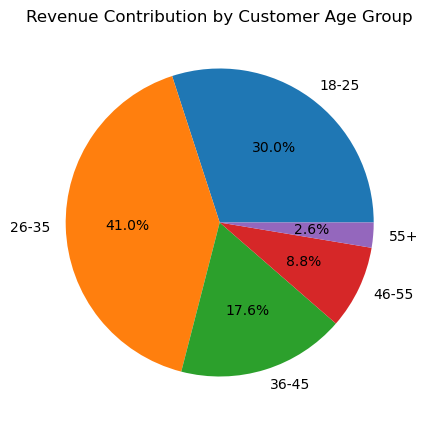

In [182]:
#total age contribution pie chart
plt.figure(figsize=(8,5))
plt.pie(age_share['final_amount_inr'],labels=age_share['customer_age_group'], autopct='%1.1f%%')
plt.title('Revenue Contribution by Customer Age Group')
plt.show()

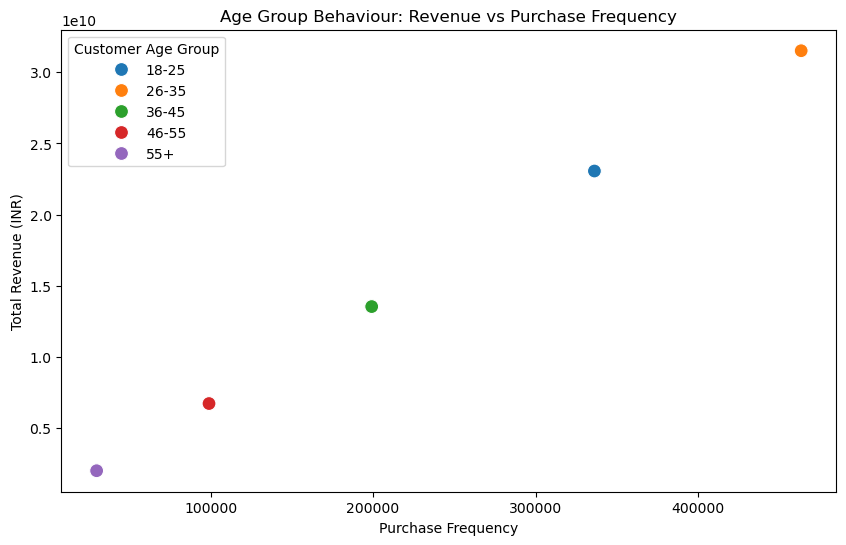

In [73]:
#Age Group Behaviour revenue vs frequency
age_group_behavior = df.groupby('customer_age_group').agg(
    total_revenue=('final_amount_inr', 'sum'),
    purchase_frequency=('transaction_id', 'count')
).reset_index()
plt.figure(figsize=(10, 6))
sns.scatterplot(data=age_group_behavior, x='purchase_frequency', y='total_revenue', s=100, hue='customer_age_group')
plt.title('Age Group Behaviour: Revenue vs Purchase Frequency')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Revenue (INR)')
plt.legend(title='Customer Age Group')
plt.show()

# Question 10

Question 10
Build price vs demand analysis using scatter plots and correlation matrices. Analyze how pricing strategies affect sales volumes across different categories and customer segments.

In [184]:
df['original_price_inr'].nunique()

14581

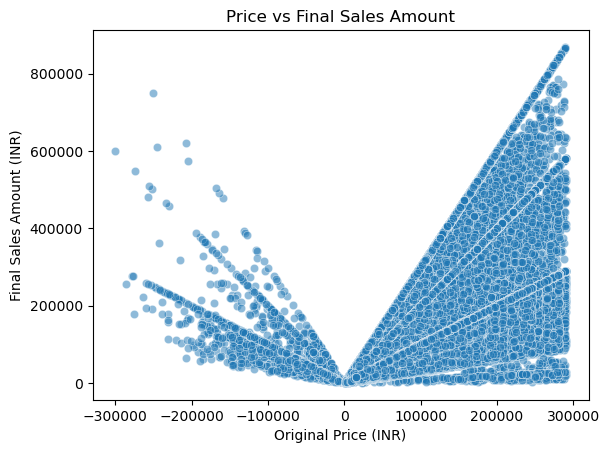

In [ ]:
#Price vs final sales amount 
sns.scatterplot(data=df, x='original_price_inr', y='final_amount_inr', alpha=0.5)
plt.title('Price vs Final Sales Amount')
plt.xlabel('Original Price (INR)')
plt.ylabel('Final Sales Amount (INR)')
plt.show()

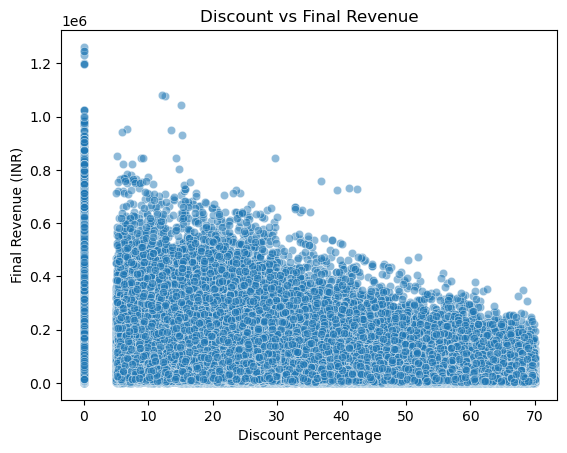

In [75]:
#Discount vs final revenue
sns.scatterplot(data=df, x='discount_percent', y='final_amount_inr', alpha=0.5)
plt.title('Discount vs Final Revenue')
plt.xlabel('Discount Percentage')
plt.ylabel('Final Revenue (INR)')
plt.show()


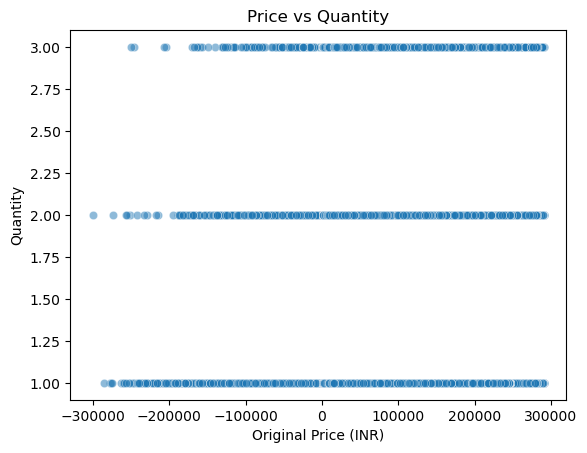

In [76]:
#price vs quantity
sns.scatterplot(data=df, x='original_price_inr', y='quantity', alpha=0.5)
plt.title('Price vs Quantity')
plt.xlabel('Original Price (INR)')
plt.ylabel('Quantity')
plt.show()

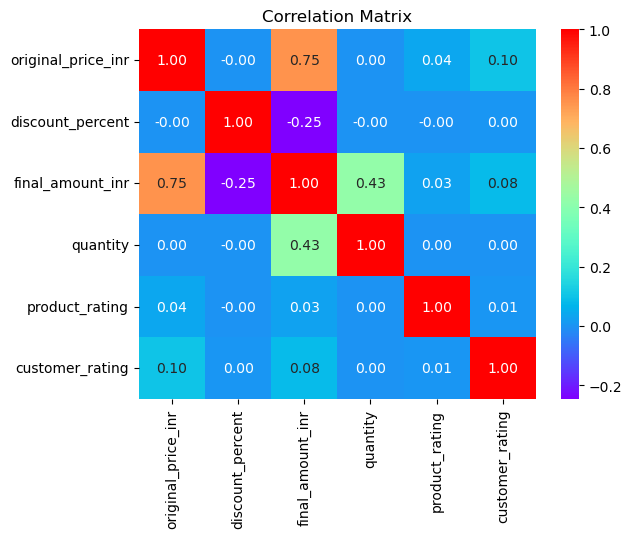

In [189]:
#Correlation Analysis
corr_cols=['original_price_inr','discount_percent',
    'final_amount_inr',
    'quantity',
    'product_rating',
    'customer_rating']
corr_matrix = df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='rainbow', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

# Question 11

Question 11
Create delivery performance analysis showing delivery days distribution, on-time performance, and customer satisfaction correlation with delivery speed across different cities and customer tiers.

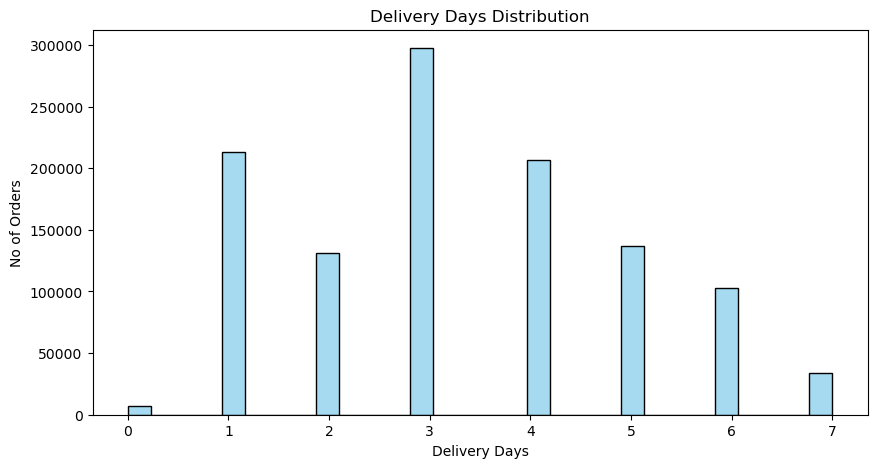

In [78]:
#Delivery days distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['delivery_days'].dropna(), bins=30, color='skyblue')
plt.title('Delivery Days Distribution')
plt.xlabel('Delivery Days')
plt.ylabel('No of Orders')
plt.show()

In [191]:
df['customer_tier'].unique()

array(['Metro', 'Rural', 'Tier2', 'Tier1'], dtype=object)

In [192]:
avg_delivery_tier = df.groupby('customer_tier')['delivery_days'].mean().reset_index()
avg_delivery_tier

,customer_tier,delivery_days
0,Metro,3.344202
1,Rural,3.437370
2,Tier1,3.222989
3,Tier2,3.321095


C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\800133097.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




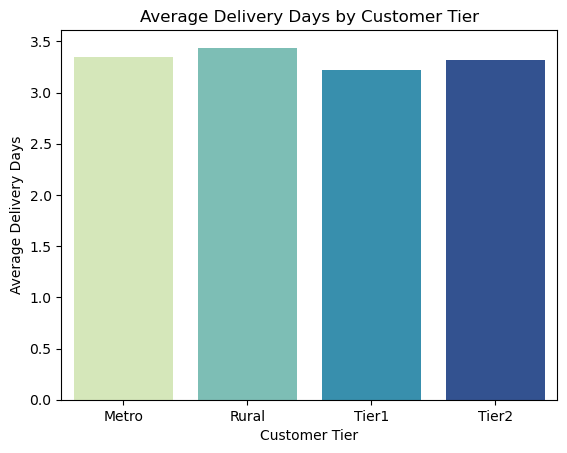

In [193]:
#Average Delivery Days by Customer Tier
sns.barplot(data=avg_delivery_tier, x='customer_tier', y='delivery_days', palette='YlGnBu')
plt.title('Average Delivery Days by Customer Tier')
plt.xlabel('Customer Tier')
plt.ylabel('Average Delivery Days')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\2986242317.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




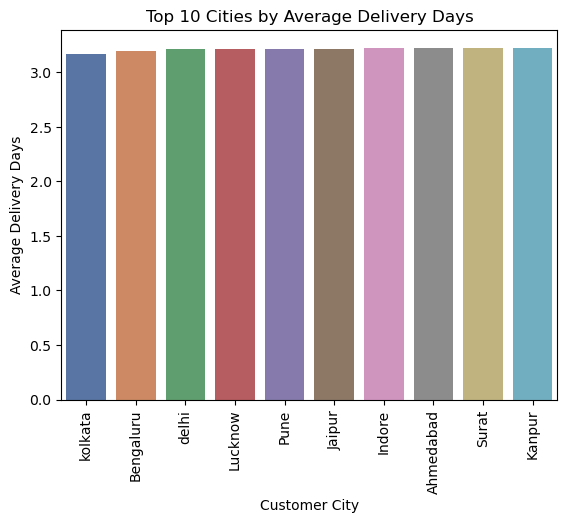

In [194]:
#Top 10 cities by average delivery days
top_cities_delivery = df.groupby('customer_city')['delivery_days'].mean().reset_index().sort_values(by='delivery_days').head(10)
sns.barplot(data=top_cities_delivery, x='customer_city', y='delivery_days', palette='deep')
plt.title('Top 10 Cities by Average Delivery Days')
plt.xlabel('Customer City')
plt.xticks(rotation=90)
plt.ylabel('Average Delivery Days')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\1964045454.py:5: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




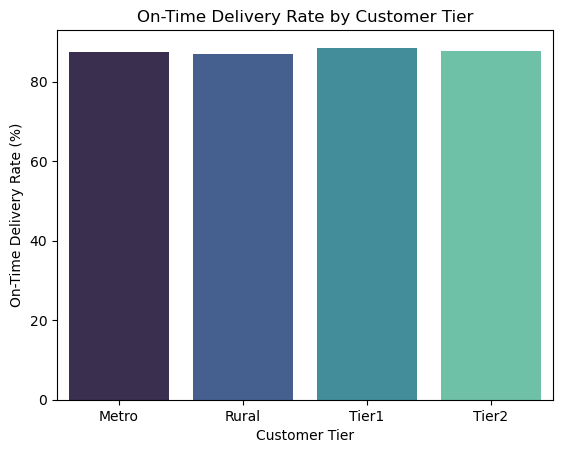

In [195]:
#on time delivery by customer tier
df['on_time_delivery'] = df['delivery_days'] <= 5
on_time_delivery_rate=df.groupby('customer_tier')['on_time_delivery'].mean().reset_index()
on_time_delivery_rate['on_time_delivery']=on_time_delivery_rate['on_time_delivery'] * 100
sns.barplot(data=on_time_delivery_rate, x='customer_tier', y='on_time_delivery', palette='mako')
plt.title('On-Time Delivery Rate by Customer Tier')
plt.xlabel('Customer Tier')
plt.ylabel('On-Time Delivery Rate (%)')
plt.show()

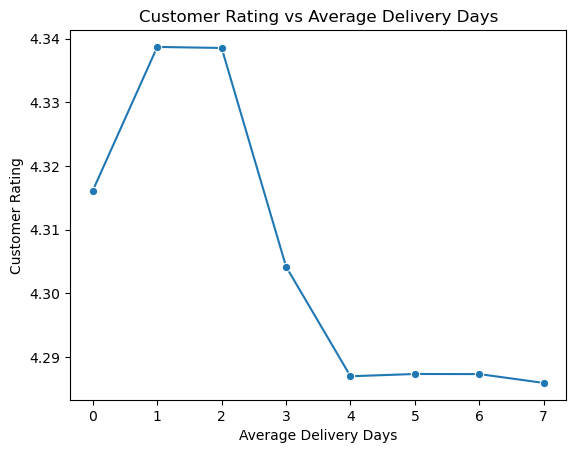

In [82]:
#customer rating vs delivery days
delivery_rating=df.groupby('delivery_days')['customer_rating'].mean().reset_index()
sns.lineplot(data=delivery_rating, x='delivery_days', y='customer_rating', marker='o')
plt.title('Customer Rating vs Average Delivery Days')
plt.xlabel('Average Delivery Days')
plt.ylabel('Customer Rating')
plt.show()

# Question 12


Question 12
Analyze return patterns and customer satisfaction using return rates, reasons, and correlation with product ratings, prices, and categories through multiple visualization techniques.

In [196]:
#order status breakdown 
return_counts=df['return_status'].value_counts()
return_counts

return_status
Delivered    1022431
Returned       79125
Cancelled      26053
Name: count, dtype: int64

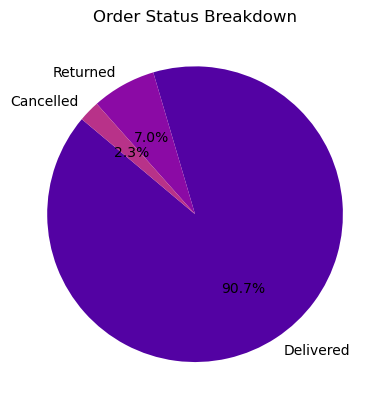

In [197]:
plt.pie(return_counts, labels=return_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('plasma'))
plt.title('Order Status Breakdown')

plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\1719549041.py:2: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\1719549041.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




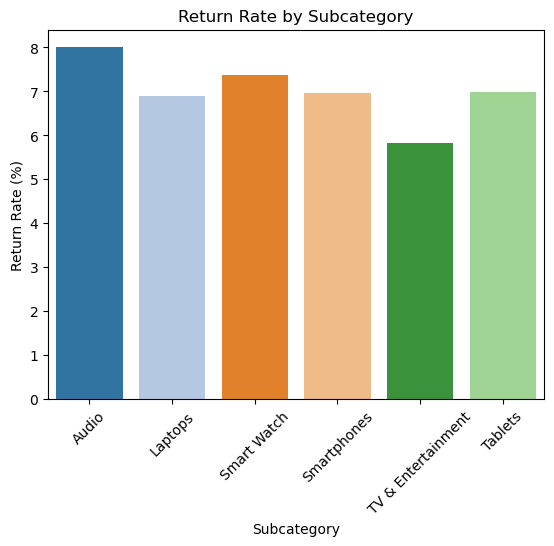

In [202]:
#Return Rate by Subcategory
return_rate_subcat = df.groupby('subcategory').apply(lambda x: (x['return_status']=='Returned').mean()*100).reset_index(name='return_rate')
sns.barplot(data=return_rate_subcat, x='subcategory', y='return_rate', palette='tab20')
plt.title('Return Rate by Subcategory')
plt.xlabel('Subcategory')
plt.ylabel('Return Rate (%)')
plt.xticks(rotation=45)
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\1001563078.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




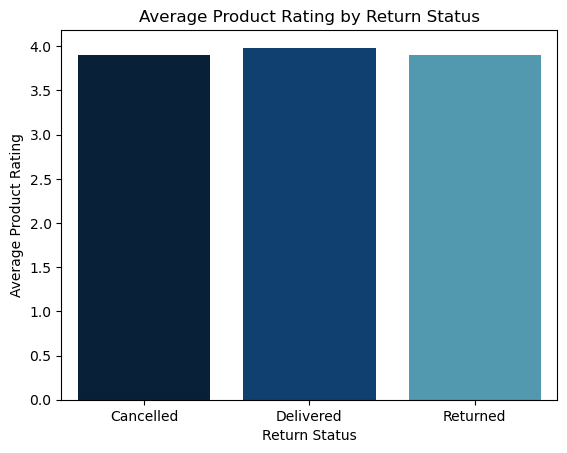

In [203]:
#Average Product Rating by Return Status
return_rating = df.groupby('return_status')['product_rating'].mean().reset_index()
sns.barplot(data=return_rating, x='return_status', y='product_rating', palette='ocean')
plt.title('Average Product Rating by Return Status')
plt.xlabel('Return Status')
plt.ylabel('Average Product Rating')
plt.show()

In [204]:
df['return_status'].unique()

array(['Delivered', 'Returned', 'Cancelled'], dtype=object)

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\4189206039.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




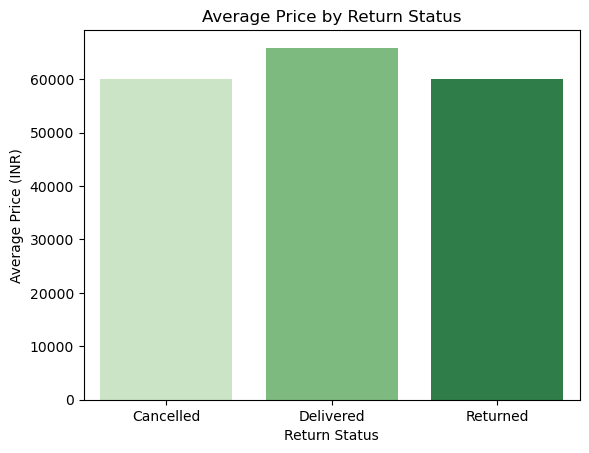

In [205]:
#Average Price by Return Status
return_price = df.groupby('return_status')['original_price_inr'].mean().reset_index()
sns.barplot(data=return_price, x='return_status', y='original_price_inr', palette='Greens')
plt.title('Average Price by Return Status')
plt.xlabel('Return Status')
plt.ylabel('Average Price (INR)')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\1005474505.py:2: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.

C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\1005474505.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




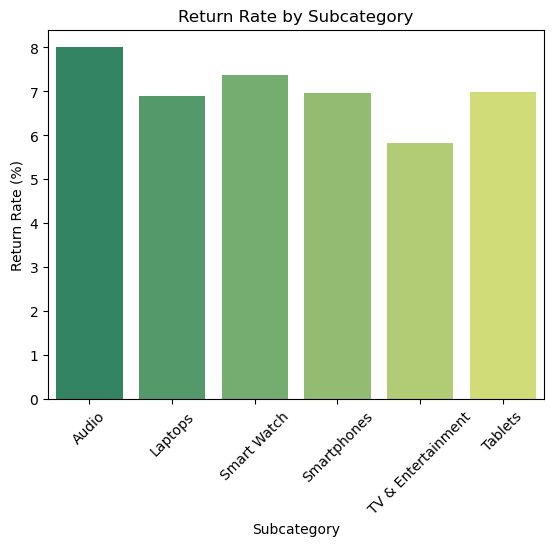

In [207]:
#Return Rate by subcategory 
return_rate_subcat = df.groupby('subcategory').apply(lambda x: (x['return_status']=='Returned').mean()*100).reset_index(name='return_rate')
sns.barplot(data=return_rate_subcat, x='subcategory', y='return_rate', palette='summer')
plt.title('Return Rate by Subcategory')
plt.xlabel('Subcategory')
plt.ylabel('Return Rate (%)')
plt.xticks(rotation=45)
plt.show()

# Question 13

Question 13
Study brand performance and market share evolution. Create brand comparison charts, market share trends, and competitive positioning analysis across different categories.

In [208]:
df['brand'].unique()

array(['Samsung', 'OnePlus', 'Motorola', 'Alienware', 'Xiaomi', 'Apple',
       'Garmin', 'Audio-Technica', 'MSI', 'LG', 'Realme', 'Noise',
       'Lenovo', 'Fitbit', 'HP', 'Acer', 'JBL', 'Dell', 'Sony',
       'Fire-Boltt', 'Sennheiser', 'ASUS', 'Boat', 'Skullcandy', 'Vivo',
       'Oppo', 'Amazfit', 'iQOO', 'Nothing'], dtype=object)

In [209]:
df['brand'].nunique()

29

In [210]:
brand_revenue=df.groupby('brand')['final_amount_inr'].sum().reset_index().sort_values(by='final_amount_inr', ascending=False).head(10)
brand_revenue

,brand,final_amount_inr
22,Samsung,2.062142e+10
4,Apple,1.632240e+10
19,OnePlus,1.232417e+10
27,Xiaomi,5.450159e+09
21,Realme,3.015664e+09
26,Vivo,2.348077e+09
20,Oppo,2.268237e+09
14,Lenovo,2.084388e+09
2,Alienware,1.659859e+09
0,ASUS,1.458950e+09


C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\470844021.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




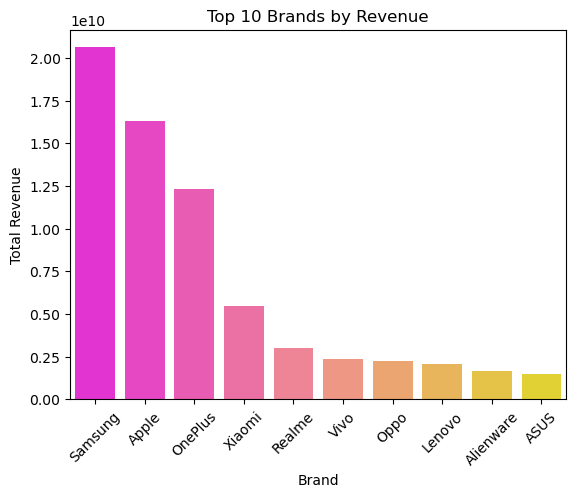

In [211]:
#Top 10 brands by revenue
sns.barplot(data=brand_revenue, x='brand', y='final_amount_inr', palette='spring')
plt.title('Top 10 Brands by Revenue')
plt.xlabel('Brand')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()


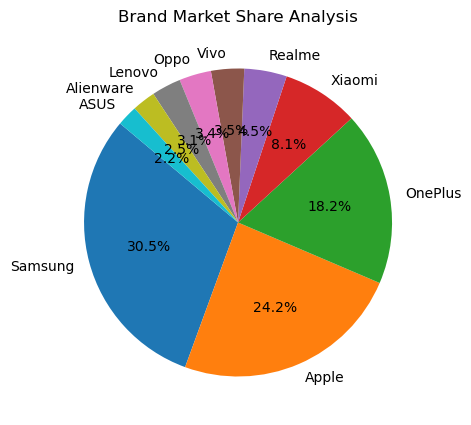

In [212]:
#Brand Market Share Analysis
plt.figure(figsize=(10, 5))
plt.pie(brand_revenue['final_amount_inr'], labels=brand_revenue['brand'], autopct='%1.1f%%', startangle=140, colors=sns.color_palette('tab10'))
plt.title('Brand Market Share Analysis')
plt.show()

In [213]:
top_5_brands = brand_revenue.head(5)['brand'].tolist()
brand_yearly = df[df['brand'].isin(top_5_brands)].groupby(['order_year', 'brand'])['final_amount_inr'].sum().reset_index()
brand_yearly

,order_year,brand,final_amount_inr
0,2015,Apple,4.249309e+08
1,2015,OnePlus,3.196321e+08
2,2015,Realme,1.378755e+06
3,2015,Samsung,6.650146e+08
4,2015,Xiaomi,1.847556e+08
5,2016,Apple,7.166985e+08
6,2016,OnePlus,6.210389e+08
7,2016,Realme,1.160833e+07
8,2016,Samsung,1.126174e+09
9,2016,Xiaomi,2.921221e+08


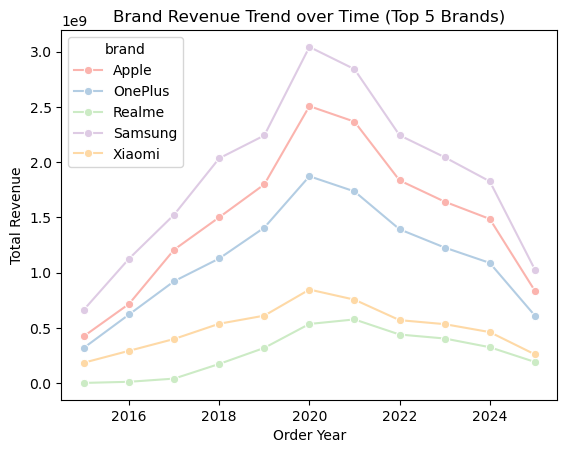

In [214]:
#Brand Revenue Trend over time (top 5 brands)
sns.lineplot(data=brand_yearly, x='order_year', y='final_amount_inr', hue='brand', palette='Pastel1', marker='o')
plt.title('Brand Revenue Trend over Time (Top 5 Brands)')
plt.xlabel('Order Year')
plt.ylabel('Total Revenue')
plt.show()

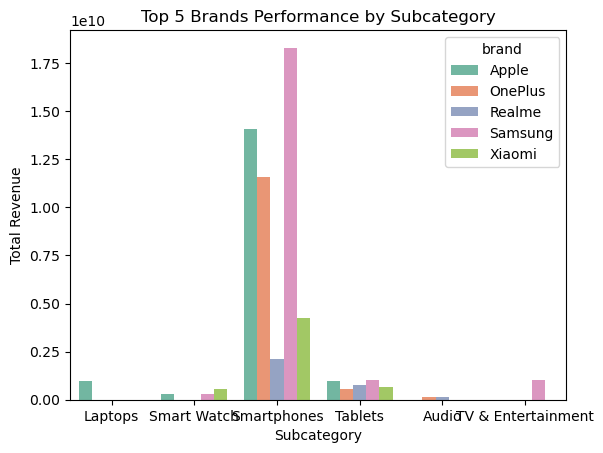

In [216]:
#brand performance by subcategory
brand_subcat_performance = df[df['brand'].isin(top_5_brands)].groupby(['brand', 'subcategory'])['final_amount_inr'].sum().reset_index()
sns.barplot(data=brand_subcat_performance, x='subcategory', y='final_amount_inr', hue='brand', palette='Set2')
plt.title('Top 5 Brands Performance by Subcategory')
plt.xlabel('Subcategory')
plt.ylabel('Total Revenue')
plt.show()

In [217]:
brand_yearly

,order_year,brand,final_amount_inr
0,2015,Apple,4.249309e+08
1,2015,OnePlus,3.196321e+08
2,2015,Realme,1.378755e+06
3,2015,Samsung,6.650146e+08
4,2015,Xiaomi,1.847556e+08
5,2016,Apple,7.166985e+08
6,2016,OnePlus,6.210389e+08
7,2016,Realme,1.160833e+07
8,2016,Samsung,1.126174e+09
9,2016,Xiaomi,2.921221e+08


C:\Users\Admin\AppData\Local\Temp\ipykernel_5588\3886185300.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




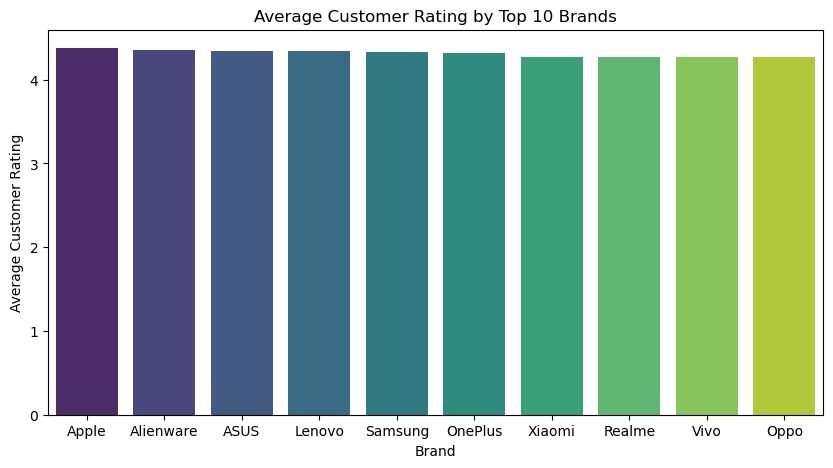

In [219]:
#Average Customer Rating by top 10 brands
plt.figure(figsize=(10, 5))
avg_brand_rating=df[df['brand'].isin(brand_revenue['brand'])].groupby('brand')['customer_rating'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=avg_brand_rating, x='brand', y='customer_rating', palette='viridis')
plt.title('Average Customer Rating by Top 10 Brands')
plt.xlabel('Brand')
plt.ylabel('Average Customer Rating')
plt.show()

In [230]:
# 1. Define the filename for your current dataset
output_file_path = 'amazon_india_progress_q13.csv'

# 2. Export the DataFrame to a CSV file
df.to_csv(output_file_path, index=False)

print(f"Progress dataset successfully saved as '{output_file_path}'!")

Progress dataset successfully saved as 'amazon_india_progress_q13.csv'!


# Question 14

Question 14
Build customer lifetime value (CLV) analysis using cohort analysis, retention curves, and CLV distribution across different customer segments and acquisition years.

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [ ]:
df['customer_id'].nunique()

354969

In [14]:
# Convert order_date into a consistent datetime format
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')

print(df['order_date'].dtype)

datetime64[ns]


In [15]:
#Find first purchase data and acquisition year per customer 
first_purchase = df.groupby('customer_id')['order_date'].min().reset_index()
first_purchase['acquisition_year'] = pd.to_datetime(first_purchase['order_date']).dt.year
first_purchase.head(10)

,customer_id,order_date,acquisition_year
0,CUST_2015_00000001,2015-09-03,2015.0
1,CUST_2015_00000002,2015-07-28,2015.0
2,CUST_2015_00000003,2015-01-05,2015.0
3,CUST_2015_00000004,2015-02-28,2015.0
4,CUST_2015_00000005,2015-01-21,2015.0
5,CUST_2015_00000006,2015-01-23,2015.0
6,CUST_2015_00000007,2015-12-05,2015.0
7,CUST_2015_00000008,2015-02-23,2015.0
8,CUST_2015_00000009,2015-02-03,2015.0
9,CUST_2015_00000010,2015-01-03,2015.0


In [16]:
clv=df.groupby('customer_id')['final_amount_inr'].sum().reset_index()
clv

,customer_id,final_amount_inr
0,CUST_2015_00000001,211034.56
1,CUST_2015_00000002,632049.52
2,CUST_2015_00000003,508294.02
3,CUST_2015_00000004,812626.53
4,CUST_2015_00000005,418011.46
...,...,...
354964,CUST_2025_00027995,67331.17
354965,CUST_2025_00027997,25770.92
354966,CUST_2025_00027998,95998.21
354967,CUST_2025_00027999,126317.28


In [17]:
#Calculate CLV (Customer Lifetime Value) total revenue per customer
clv.columns=['customer_id', 'clv']
clv = clv.merge(first_purchase[['customer_id', 'acquisition_year']], on='customer_id')
clv.head()



,customer_id,clv,acquisition_year
0,CUST_2015_00000001,211034.56,2015.0
1,CUST_2015_00000002,632049.52,2015.0
2,CUST_2015_00000003,508294.02,2015.0
3,CUST_2015_00000004,812626.53,2015.0
4,CUST_2015_00000005,418011.46,2015.0


C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\233787867.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=clv_by_year, x='acquisition_year',y='clv',palette='plasma')


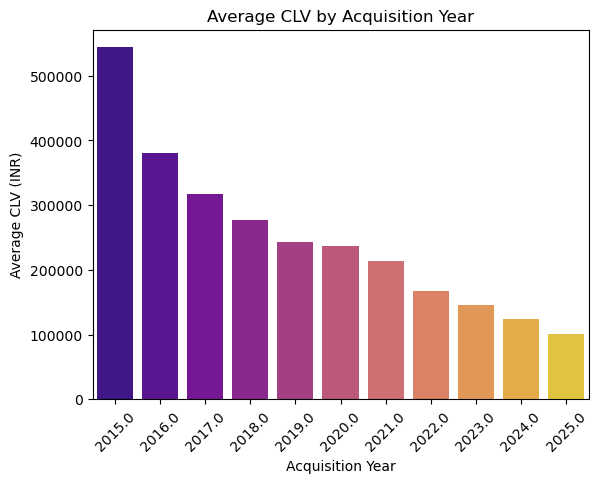

In [18]:
#Average CLV by acquistion year
clv_by_year=clv.groupby('acquisition_year')['clv'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=clv_by_year, x='acquisition_year',y='clv',palette='plasma')
plt.title('Average CLV by Acquisition Year')
plt.xlabel('Acquisition Year')
plt.xticks(rotation=45)
plt.ylabel('Average CLV (INR)')
plt.show()

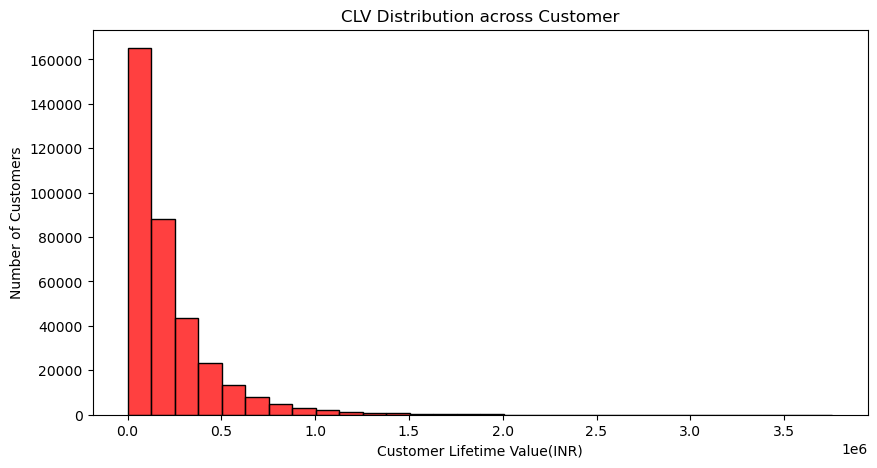

In [19]:
#CLV Distribution
plt.figure(figsize=(10,5))
sns.histplot(clv['clv'],bins=30,color='red')
plt.title('CLV Distribution across Customer')
plt.xlabel('Customer Lifetime Value(INR)')
plt.ylabel('Number of Customers')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\975644266.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=retention_dist.index,y=retention_dist.values,palette='rocket')


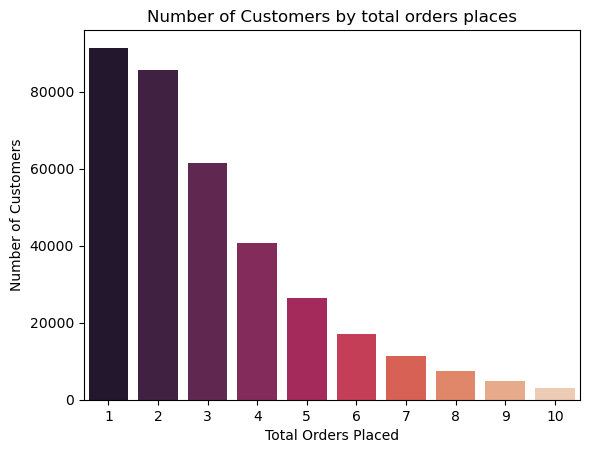

In [24]:
#Customer Retention: Orders per customer distribution (as a retention proxy)
order_counts=df.groupby('customer_id')['transaction_id'].count().reset_index(name='total_orders')
retention_dist=order_counts['total_orders'].value_counts().sort_index().head(10)
sns.barplot(x=retention_dist.index,y=retention_dist.values,palette='rocket')
plt.title('Number of Customers by total orders places')
plt.xlabel('Total Orders Placed')
plt.ylabel('Number of Customers')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\4206067814.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=clv_tier, x='customer_spending_tier', y='final_amount_inr', palette='cool')


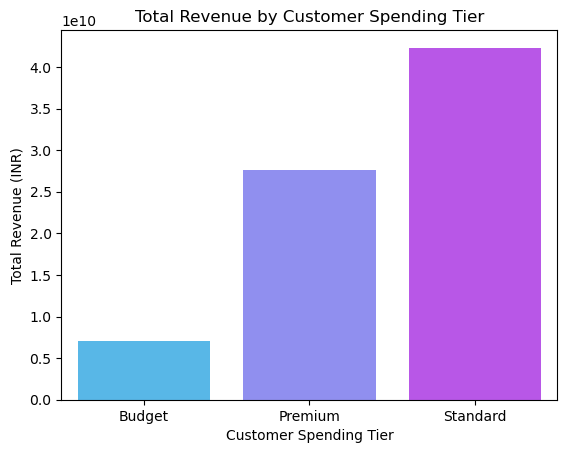

In [23]:
#CLV by Customer Spending Tier
clv_tier = df.groupby('customer_spending_tier')['final_amount_inr'].sum().reset_index()
sns.barplot(data=clv_tier, x='customer_spending_tier', y='final_amount_inr', palette='cool')
plt.title('Total Revenue by Customer Spending Tier')
plt.xlabel('Customer Spending Tier')
plt.ylabel('Total Revenue (INR)')
plt.show()

Question 15
Analyze discount and promotional effectiveness. Create discount impact analysis showing correlation between discount percentages, sales volumes, and revenue across categories and time periods.

In [25]:
df['discount_percent'].unique()

array([27.91,  0.  , 46.93, ..., 54.98, 66.69, 65.66], shape=(6502,))

In [27]:
#Bucket discount percentages into bands
discount_bins = pd.cut(df['discount_percent'], bins=[-1,0,10,20,30,40,100],
                        labels=['0%','1-10%','11-20%','21-30%','31-40%','40%+'])
df['discount_band'] = discount_bins

In [28]:
discount_orders = df.groupby('discount_band', observed=True).size().reset_index(name='orders')
discount_orders

,discount_band,orders
0,0%,505903
1,1-10%,53985
2,11-20%,140455
3,21-30%,172913
4,31-40%,63242
5,40%+,191111


C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\2236070178.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=discount_orders, x='discount_band', y='orders', palette='flare')


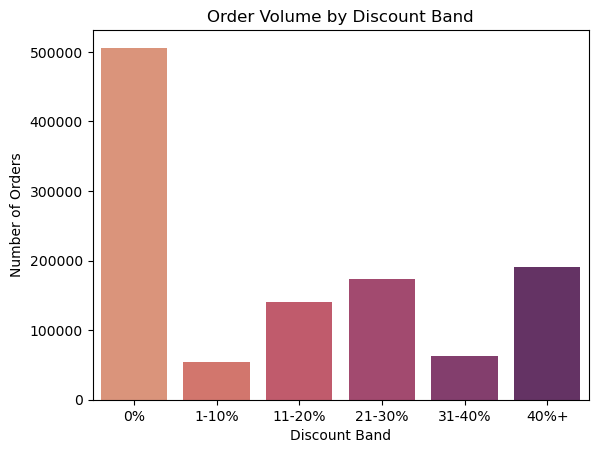

In [30]:
#Order Volume by Discount Band
sns.barplot(data=discount_orders, x='discount_band', y='orders', palette='flare')
plt.title('Order Volume by Discount Band')
plt.xlabel('Discount Band')
plt.ylabel('Number of Orders')
plt.show()

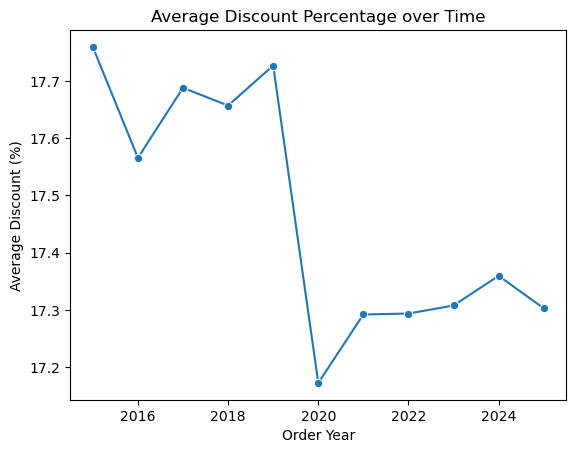

In [102]:
#Discount Trend over Time
discount_year = df.groupby('order_year')['discount_percent'].mean().reset_index()
sns.lineplot(data=discount_year, x='order_year', y='discount_percent', marker='o')
plt.title('Average Discount Percentage over Time')
plt.xlabel('Order Year')
plt.ylabel('Average Discount (%)')
plt.show()

In [31]:
discount_cat = df.groupby(['category', 'discount_band'], observed=True)['final_amount_inr'].sum().reset_index()
discount_cat

,category,discount_band,final_amount_inr
0,Electronics,0%,4.178709e+10
1,Electronics,1-10%,4.127891e+09
2,Electronics,11-20%,9.775511e+09
3,Electronics,21-30%,1.071164e+10
4,Electronics,31-40%,3.399635e+09
5,Electronics,40%+,7.086965e+09


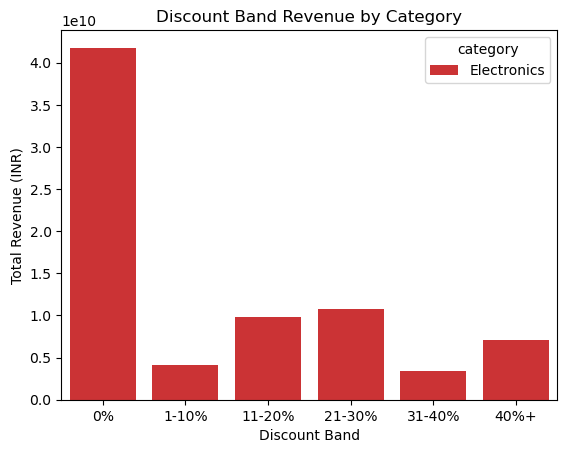

In [34]:
#Discount Band Revenue by Category
sns.barplot(data=discount_cat, x='discount_band', y='final_amount_inr', hue='category', palette='Set1')
plt.title('Discount Band Revenue by Category')
plt.xlabel('Discount Band')
plt.ylabel('Total Revenue (INR)')
plt.show()

Question 16
Study product rating patterns and their impact on sales. Analyze rating distributions, correlation with sales performance, and identify patterns across categories and price ranges.

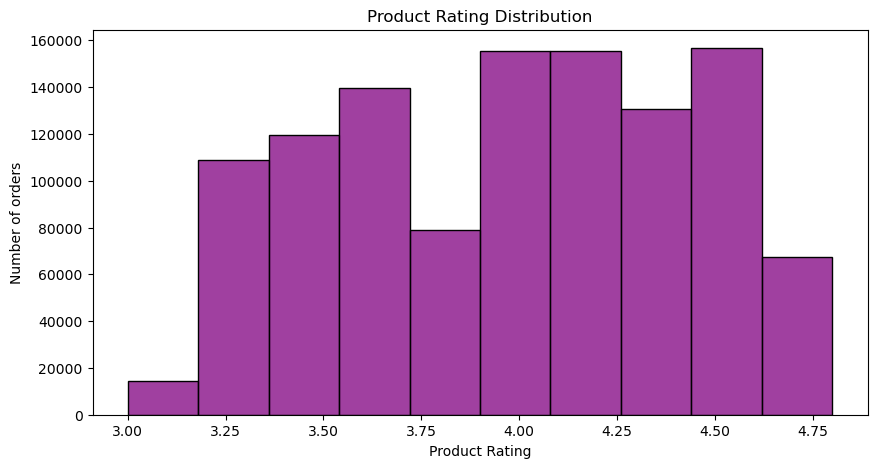

In [35]:
#Product Rating Distribution 
plt.figure(figsize=(10,5))
sns.histplot(df['product_rating'].dropna(),bins=10,color='purple')
plt.title('Product Rating Distribution')
plt.xlabel('Product Rating')
plt.ylabel('Number of orders')
plt.show()

In [36]:
rating_sales= df.groupby('product_rating')['transaction_id'].count().reset_index()
rating_sales

,product_rating,transaction_id
0,3.0,6700
1,3.1,7832
2,3.2,40194
3,3.3,68674
4,3.4,56497
5,3.5,63162
6,3.6,73098
7,3.7,66430
8,3.8,79047
9,3.9,67886


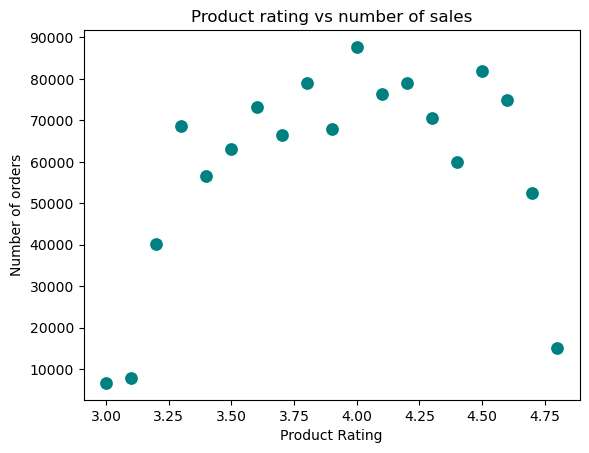

In [38]:
#Order by product rating
rating_sales= df.groupby('product_rating')['transaction_id'].count().reset_index()
sns.scatterplot(data=rating_sales,x='product_rating',y='transaction_id',s=100,color='teal')
plt.title('Product rating vs number of sales')
plt.xlabel('Product Rating')
plt.ylabel('Number of orders')
plt.show()

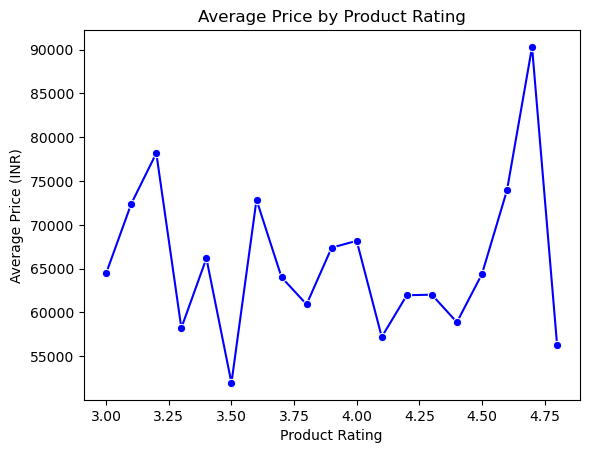

In [40]:
#Average Price by Product Rating
rating_price = df.groupby('product_rating')['original_price_inr'].mean().reset_index()
sns.lineplot(data=rating_price, x='product_rating', y='original_price_inr', marker='o', color='blue')
plt.title('Average Price by Product Rating')
plt.xlabel('Product Rating')
plt.ylabel('Average Price (INR)')
plt.show()

In [41]:
rating_cat = df.groupby('category')['product_rating'].mean().reset_index()
rating_cat

,category,product_rating
0,Electronics,3.975245


C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\453335824.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rating_cat, x='category', y='product_rating', palette='mako')


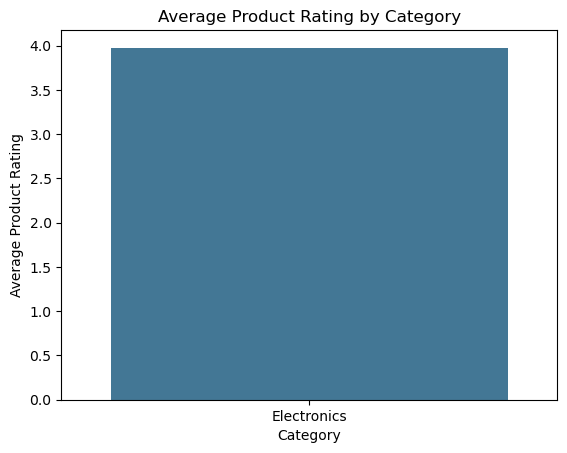

In [43]:
#Product Rating by Category
rating_cat = df.groupby('category')['product_rating'].mean().reset_index()
sns.barplot(data=rating_cat, x='category', y='product_rating', palette='mako')
plt.title('Average Product Rating by Category')
plt.xlabel('Category')
plt.ylabel('Average Product Rating')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\914141791.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rating_revenue, x='product_rating', y='final_amount_inr', palette='mako')


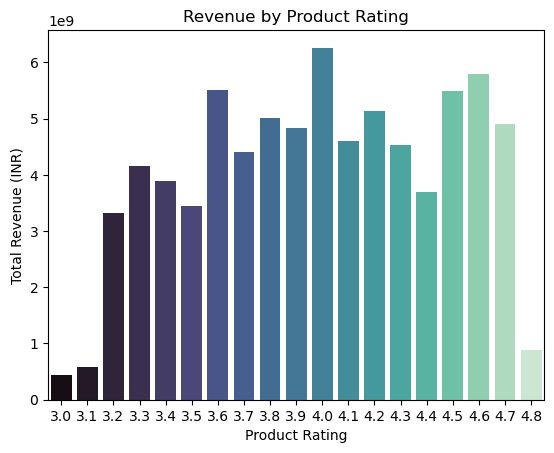

In [45]:
#Revenue by Product Rating
rating_revenue = df.groupby('product_rating')['final_amount_inr'].sum().reset_index()
sns.barplot(data=rating_revenue, x='product_rating', y='final_amount_inr', palette='mako')
plt.title('Revenue by Product Rating')
plt.xlabel('Product Rating')
plt.ylabel('Total Revenue (INR)')
plt.show()

Question 17
Create customer journey analysis showing purchase frequency patterns, category transitions, and customer evolution from first purchase to loyal customers using flow diagrams and transition matrices.

In [46]:

#Order Sequence per Customer
order_seq = df.sort_values(['customer_id', 'order_date']).copy()
order_seq['order_number'] = order_seq.groupby('customer_id').cumcount() + 1
order_seq[['customer_id', 'order_date', 'order_number']].head()



,customer_id,order_date,order_number
20422,CUST_2015_00000001,2015-09-03,1
22190,CUST_2015_00000001,2015-09-05,2
29409,CUST_2015_00000001,2015-12-17,3
206165,CUST_2015_00000001,2018-06-17,4
262170,CUST_2015_00000001,2018-12-15,5


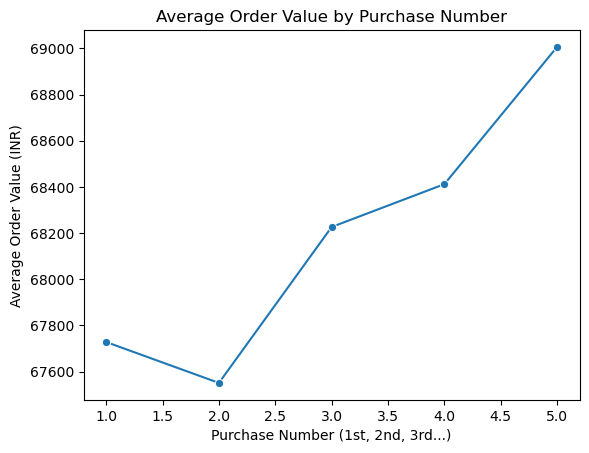

In [47]:
#Average Order Value by Order Number (1st, 2nd, 3rd purchase...)
aov_by_ordernum = order_seq[order_seq['order_number'] <= 5].groupby('order_number')['final_amount_inr'].mean().reset_index()
sns.lineplot(data=aov_by_ordernum, x='order_number', y='final_amount_inr', marker='o')
plt.title('Average Order Value by Purchase Number')
plt.xlabel('Purchase Number (1st, 2nd, 3rd...)')
plt.ylabel('Average Order Value (INR)')
plt.show()

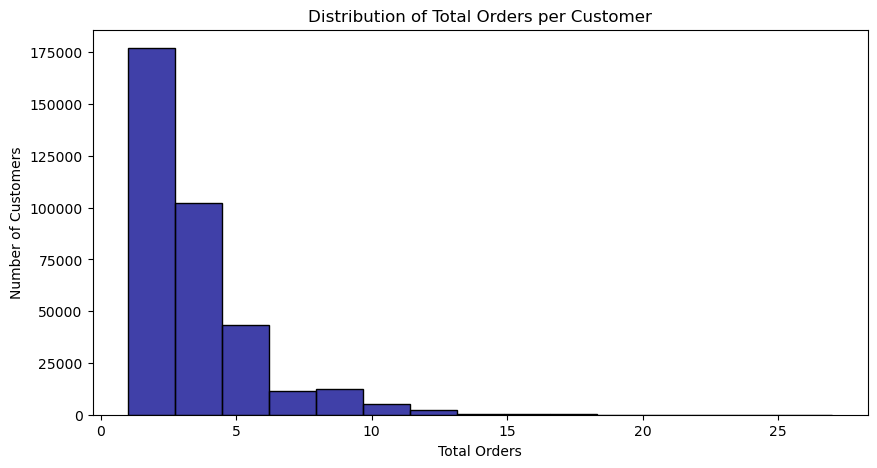

In [48]:
#Customer Loyalty: Distribution of Total Orders per Customer
cust_order_counts = df.groupby('customer_id')['transaction_id'].count().reset_index(name='total_orders')
plt.figure(figsize=(10,5))
sns.histplot(cust_order_counts['total_orders'], bins=15, color='darkblue')
plt.title('Distribution of Total Orders per Customer')
plt.xlabel('Total Orders')
plt.ylabel('Number of Customers')
plt.show()

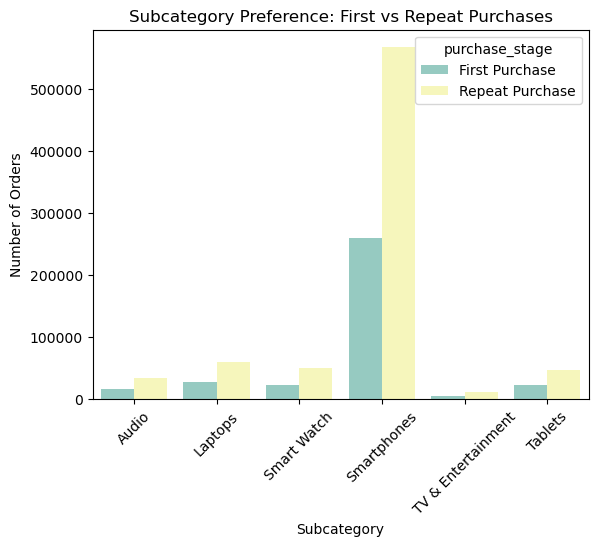

In [49]:
#Category Preference: First Purchase vs Later Purchases
first_vs_later = order_seq.copy()
first_vs_later['purchase_stage'] = first_vs_later['order_number'].apply(lambda x: 'First Purchase' if x == 1 else 'Repeat Purchase')
stage_category = first_vs_later.groupby(['purchase_stage', 'subcategory'])['transaction_id'].count().reset_index(name='orders')
sns.barplot(data=stage_category, x='subcategory', y='orders', hue='purchase_stage', palette='Set3')
plt.title('Subcategory Preference: First vs Repeat Purchases')
plt.xlabel('Subcategory')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.show()

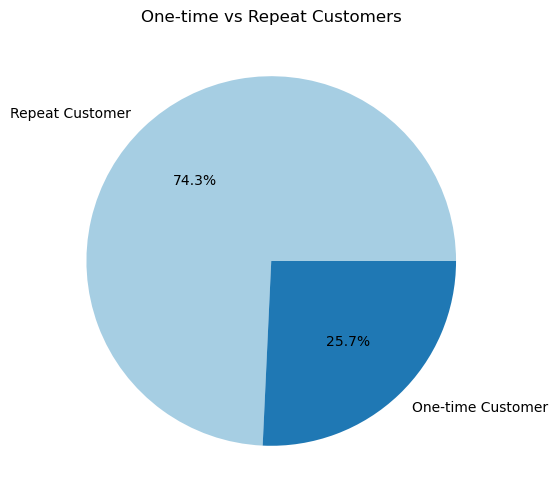

In [51]:
#One-time vs Repeat Customers
cust_order_counts['customer_type'] = cust_order_counts['total_orders'].apply(lambda x: 'One-time Customer' if x == 1 else 'Repeat Customer')
plt.figure(figsize=(6,6))
plt.pie(cust_order_counts['customer_type'].value_counts().values,
        labels=cust_order_counts['customer_type'].value_counts().index,
        autopct='%1.1f%%', colors=sns.color_palette('Paired'))
plt.title('One-time vs Repeat Customers')
plt.show()

# Question 18

Question 18
Analyze inventory and product lifecycle patterns. Study product launch success, decline phases, and category evolution over the decade with detailed trend analysis.

In [53]:
#Find each product's first sale date (proxy for launch)
product_launch = df.groupby('product_id')['order_date'].min().reset_index()
product_launch['launch_year'] = pd.to_datetime(product_launch['order_date']).dt.year
product_launch.head()

,product_id,order_date,launch_year
0,PROD_000001,2015-01-03,2015
1,PROD_000002,2015-01-15,2015
2,PROD_000003,2015-01-01,2015
3,PROD_000004,2015-01-01,2015
4,PROD_000005,2015-01-01,2015


C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\1355759242.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=launches_per_year.index, y=launches_per_year.values, palette='magma')


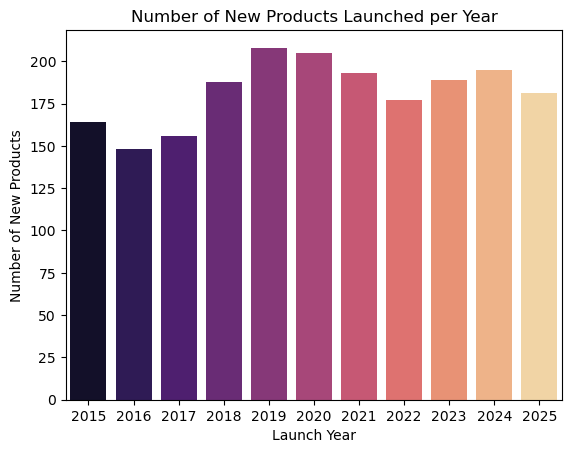

In [56]:
#Number of New Products Launched per Year
launches_per_year = product_launch['launch_year'].value_counts().sort_index()
sns.barplot(x=launches_per_year.index, y=launches_per_year.values, palette='magma')
plt.title('Number of New Products Launched per Year')
plt.xlabel('Launch Year')
plt.ylabel('Number of New Products')
plt.show()

In [57]:
category_evo = df.groupby(['order_year', 'category'])['final_amount_inr'].sum().reset_index()
category_evo

,order_year,category,final_amount_inr
0,2015,Electronics,2.142163e+09
1,2016,Electronics,3.598316e+09
2,2017,Electronics,5.510026e+09
3,2018,Electronics,7.248545e+09
4,2019,Electronics,8.605901e+09
5,2020,Electronics,1.187319e+10
6,2021,Electronics,1.099021e+10
7,2022,Electronics,8.532312e+09
8,2023,Electronics,7.712999e+09
9,2024,Electronics,6.823413e+09


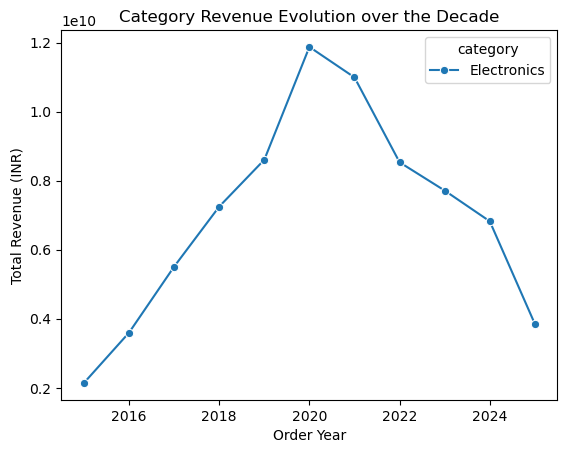

In [58]:
#Category Revenue Evolution over the Decade
sns.lineplot(data=category_evo, x='order_year', y='final_amount_inr', hue='category', marker='o')
plt.title('Category Revenue Evolution over the Decade')
plt.xlabel('Order Year')
plt.ylabel('Total Revenue (INR)')
plt.show()

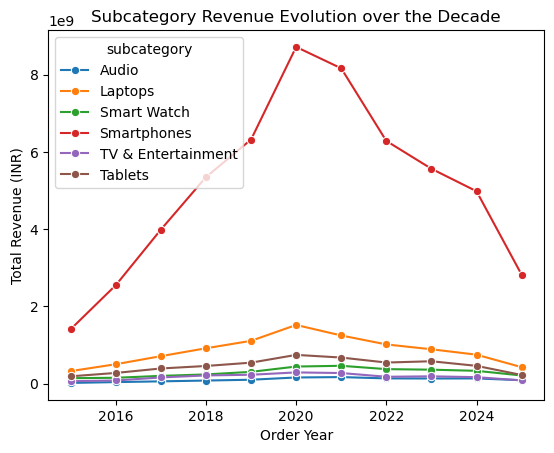

In [59]:
#Subcategory Revenue Evolution over the Decade
subcat_evo = df.groupby(['order_year', 'subcategory'])['final_amount_inr'].sum().reset_index()
sns.lineplot(data=subcat_evo, x='order_year', y='final_amount_inr', hue='subcategory', marker='o')
plt.title('Subcategory Revenue Evolution over the Decade')
plt.xlabel('Order Year')
plt.ylabel('Total Revenue (INR)')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\3504935095.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=product_years_active, x='years_active', y='product_id', palette='rocket')


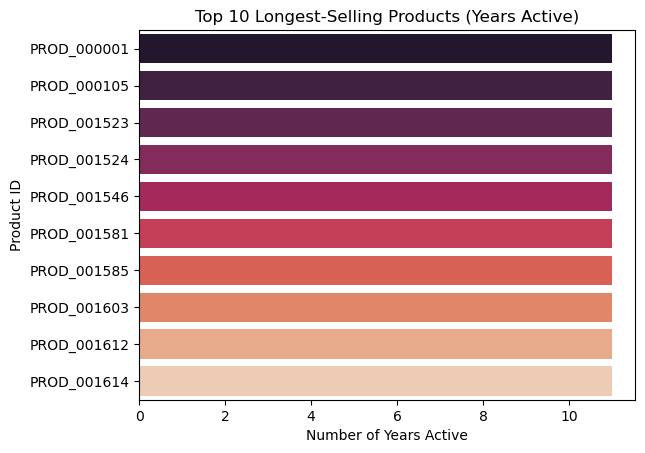

In [63]:
#Top 10 Longest-Selling Products (Years Active)
product_years_active = df.groupby('product_id')['order_year'].nunique().sort_values(ascending=False).head(10).reset_index()
product_years_active.columns = ['product_id', 'years_active']
sns.barplot(data=product_years_active, x='years_active', y='product_id', palette='rocket')
plt.title('Top 10 Longest-Selling Products (Years Active)')
plt.xlabel('Number of Years Active')
plt.ylabel('Product ID')
plt.show()

# Question 19

Question 19
Build competitive pricing analysis comparing brand positioning, price ranges, and market penetration strategies across different product categories using box plots and competitive matrices.

C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\823384018.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=brand_price, x='original_price_inr', y='brand', palette='plasma')


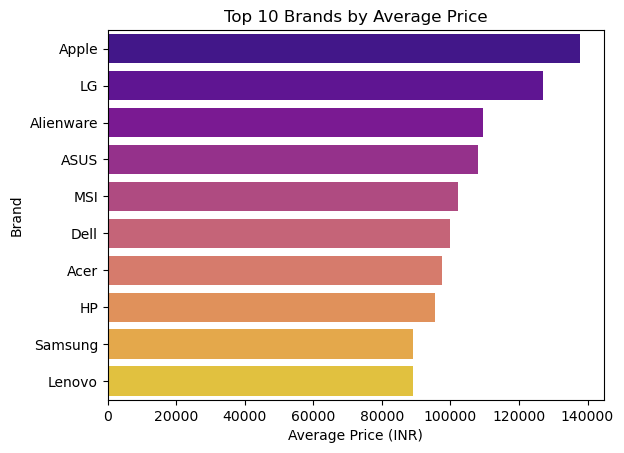

In [64]:
#Top 10 Brands by Average Price
brand_price = df.groupby('brand')['original_price_inr'].mean().sort_values(ascending=False).head(10).reset_index()
sns.barplot(data=brand_price, x='original_price_inr', y='brand', palette='plasma')
plt.title('Top 10 Brands by Average Price')
plt.xlabel('Average Price (INR)')
plt.ylabel('Brand')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\2686474768.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=box_df, x='brand', y='original_price_inr', palette='Set1')


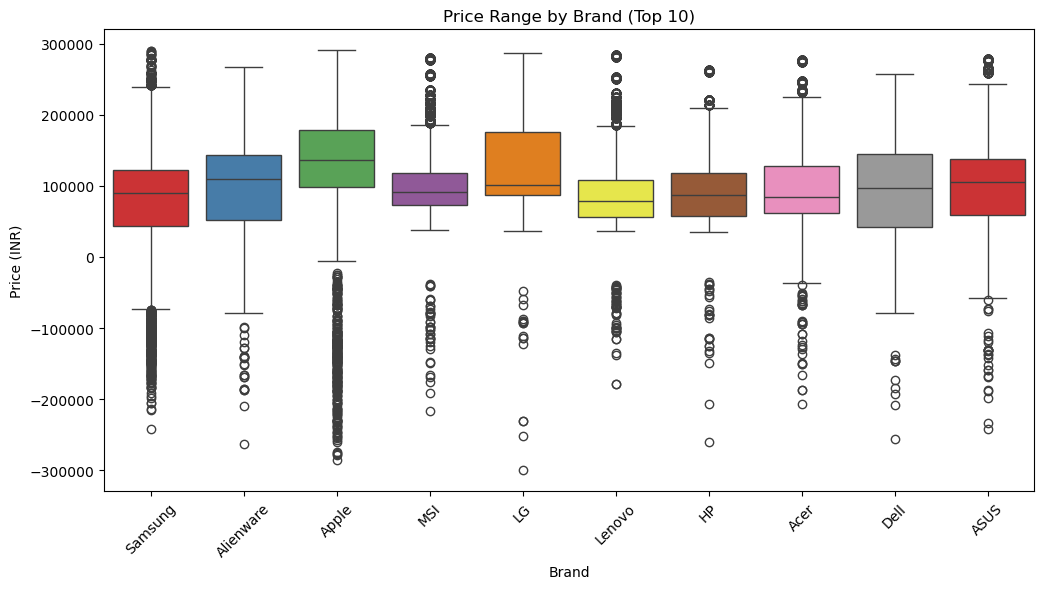

In [65]:
#Price Range by Brand (Box Plot)
top10_brands = brand_price['brand'].tolist()
box_df = df[df['brand'].isin(top10_brands)]
plt.figure(figsize=(12,6))
sns.boxplot(data=box_df, x='brand', y='original_price_inr', palette='Set1')
plt.title('Price Range by Brand (Top 10)')
plt.xlabel('Brand')
plt.ylabel('Price (INR)')
plt.xticks(rotation=45)
plt.show()

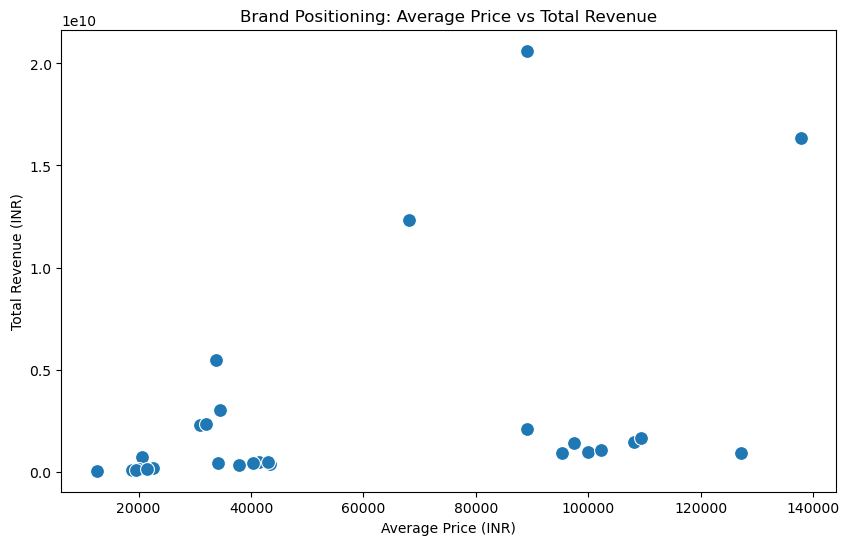

In [121]:
#Brand Positioning: Average Price vs Total Revenue
brand_position = df.groupby('brand').agg(
    avg_price=('original_price_inr', 'mean'),
    total_revenue=('final_amount_inr', 'sum')
).reset_index()
plt.figure(figsize=(10,6))
sns.scatterplot(data=brand_position, x='avg_price', y='total_revenue', s=100)
plt.title('Brand Positioning: Average Price vs Total Revenue')
plt.xlabel('Average Price (INR)')
plt.ylabel('Total Revenue (INR)')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\2482483278.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=brand_penetration, x='cities_reached', y='brand', palette='autumn')


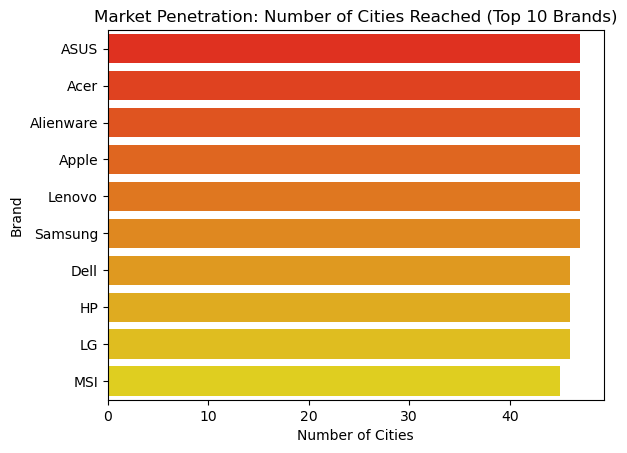

In [70]:
#Market Penetration: Number of Cities Reached by Brand (Top 10)
brand_penetration = df[df['brand'].isin(top10_brands)].groupby('brand')['customer_city'].nunique().sort_values(ascending=False).reset_index()
brand_penetration.columns = ['brand', 'cities_reached']
sns.barplot(data=brand_penetration, x='cities_reached', y='brand', palette='autumn')
plt.title('Market Penetration: Number of Cities Reached (Top 10 Brands)')
plt.xlabel('Number of Cities')
plt.ylabel('Brand')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_18628\2859408349.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='subcategory', y='original_price_inr', palette='husl')


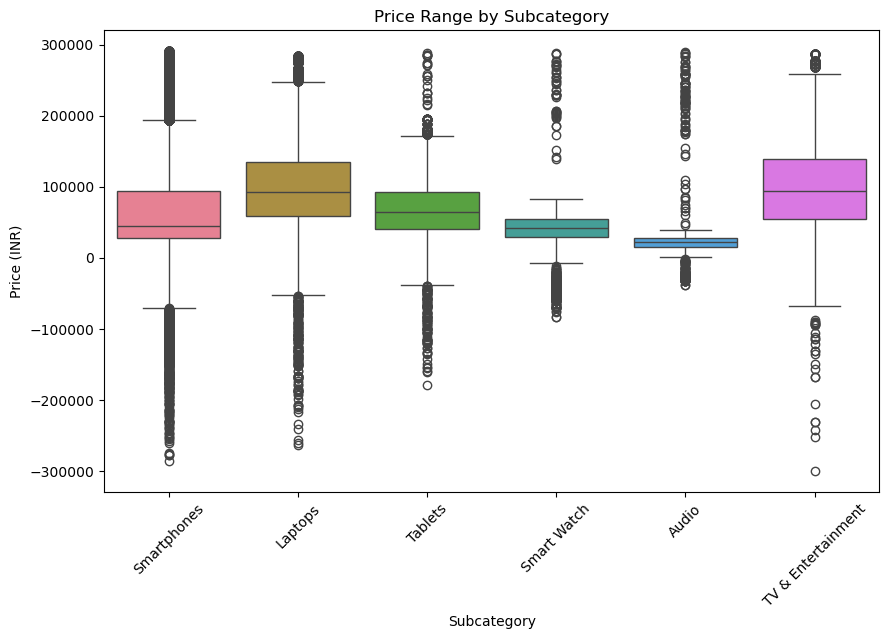

In [71]:
#Price Range by Subcategory (Box Plot)
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='subcategory', y='original_price_inr', palette='husl')
plt.title('Price Range by Subcategory')
plt.xlabel('Subcategory')
plt.ylabel('Price (INR)')
plt.xticks(rotation=45)
plt.show()

# Question 20

Question 20
Create a comprehensive business health dashboard combining key metrics like revenue growth, customer acquisition, retention rates, and operational efficiency using multi-panel visualizations with executive summary insights.

In [73]:
#Yearly KPI Summary Table
kpi_year = df.groupby('order_year').agg(
    revenue=('final_amount_inr', 'sum'),
    customers=('customer_id', 'nunique'),
    orders=('transaction_id', 'count'),
    avg_order_value=('final_amount_inr', 'mean'),
    return_rate=('return_status', lambda x: (x == 'Returned').mean() * 100)
).reset_index()

kpi_year['growth_%'] = kpi_year['revenue'].pct_change() * 100
kpi_year

,order_year,revenue,customers,orders,avg_order_value,return_rate,growth_%
0,2015,2.142163e+09,11222,33165,64591.089351,7.085783,NaN
1,2016,3.598316e+09,26273,55275,65098.431828,6.843962,67.975780
2,2017,5.510026e+09,38789,77385,71202.761606,7.025909,53.127907
3,2018,7.248545e+09,49917,99495,72853.358575,6.977235,31.551925
4,2019,8.605901e+09,61068,121605,70769.300522,6.889519,18.725908
5,2020,1.187319e+10,71997,143715,82616.249430,6.926904,37.965735
6,2021,1.099021e+10,69375,138187,79531.430632,7.025987,-7.436790
7,2022,8.532312e+09,66605,132660,64317.144175,7.101613,-22.364427
8,2023,7.712999e+09,63790,127132,60669.217705,7.203536,-9.602477
9,2024,6.823413e+09,60947,121605,56111.288750,7.000535,-11.533590


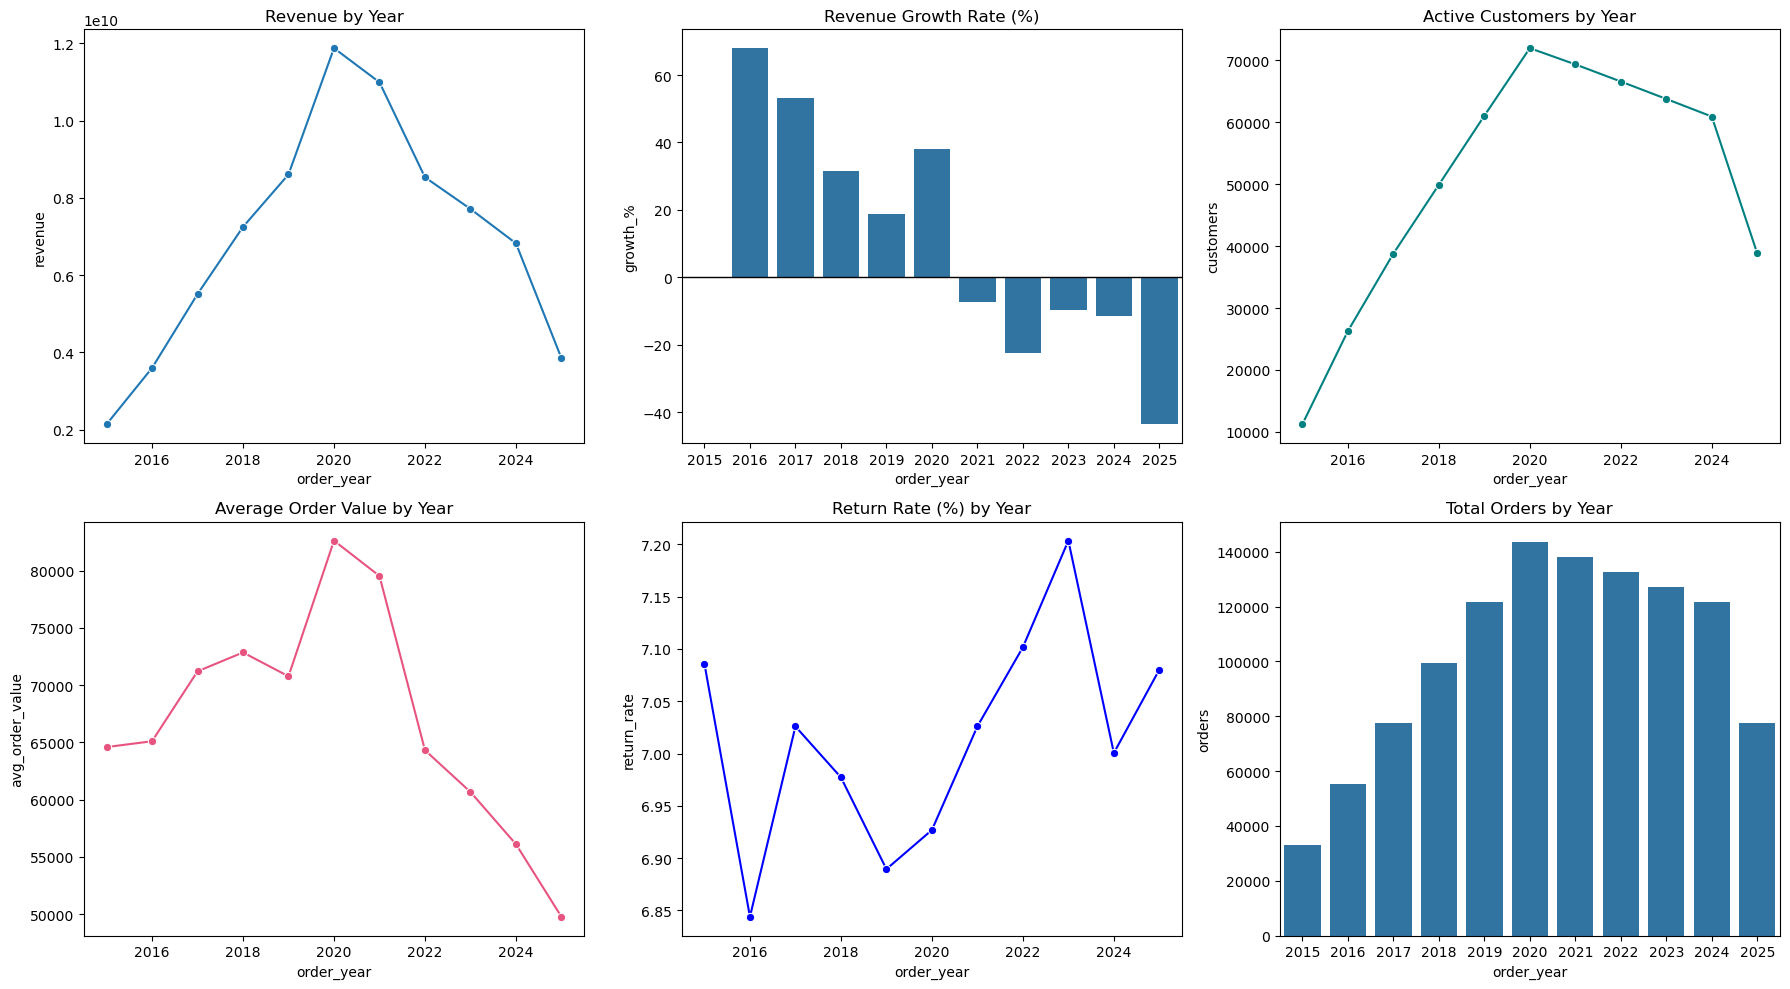

In [78]:
#Multi-Panel Business Health Dashboard
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.lineplot(data=kpi_year, x='order_year', y='revenue', marker='o', ax=axes[0,0])
axes[0,0].set_title('Revenue by Year')

sns.barplot(data=kpi_year, x='order_year', y='growth_%', ax=axes[0,1])
axes[0,1].set_title('Revenue Growth Rate (%)')
axes[0,1].axhline(0, color='black', linewidth=1)

sns.lineplot(data=kpi_year, x='order_year', y='customers', marker='o', color='teal', ax=axes[0,2])
axes[0,2].set_title('Active Customers by Year')

sns.lineplot(data=kpi_year, x='order_year', y='avg_order_value', marker='o', color='#E75480', ax=axes[1,0])
axes[1,0].set_title('Average Order Value by Year')

sns.lineplot(data=kpi_year, x='order_year', y='return_rate', marker='o', color='blue', ax=axes[1,1])
axes[1,1].set_title('Return Rate (%) by Year')

sns.barplot(data=kpi_year, x='order_year', y='orders', ax=axes[1,2])
axes[1,2].set_title('Total Orders by Year')

plt.tight_layout()
plt.show()

In [79]:
#Executive Summary Metrics
total_revenue = df['final_amount_inr'].sum()
total_customers = df['customer_id'].nunique()
total_orders = df['transaction_id'].count()
avg_order_value = df['final_amount_inr'].mean()
overall_return_rate = (df['return_status'] == 'Returned').mean() * 100

print(f'Total Revenue: Rs. {total_revenue:,.0f}')
print(f'Total Customers: {total_customers:,}')
print(f'Total Orders: {total_orders:,}')
print(f'Average Order Value: Rs. {avg_order_value:,.0f}')
print(f'Overall Return Rate: {overall_return_rate:.2f}%')

Total Revenue: Rs. 76,888,729,563
Total Customers: 354,969
Total Orders: 1,127,609
Average Order Value: Rs. 68,187
Overall Return Rate: 7.02%


In [80]:
df.shape

(1127609, 36)

In [81]:
# Save the current dataset
output_file_path = 'eda_completed.csv'
df.to_csv(output_file_path, index=False)

print(f"Progress dataset successfully saved as '{output_file_path}'!")
print("EDA completed")

Progress dataset successfully saved as 'eda_completed.csv'!
EDA completed
